# Доклад по теме «Модификации LSTM: применение xLSTM для прогнозирования временных рядов»

Поскольку LSTM сохраняет состояние памяти, применение данного семейства для временных рядов вполне обоснованно.

Для исследования я взяла [датасет фондового рынка США](https://www.kaggle.com/datasets/borismarjanovic/price-volume-data-for-all-us-stocks-etfs/data?select=ETFs) для предсказания стоимости закрытия акций.

In [1]:
%pip -q install kagglehub

Note: you may need to restart the kernel to use updated packages.


In [2]:
import kagglehub
from pathlib import Path
import pandas as pd


dataset_path = Path(kagglehub.dataset_download(
    "borismarjanovic/price-volume-data-for-all-us-stocks-etfs"
))

stocks = ["AAPL", "SPY", "GE", "IBM"]
tables = {}

for stock in stocks:
    filename = stock.lower() + ".us.txt"
    path = list(dataset_path.rglob(filename))[0]
    tables[stock] = pd.read_csv(path, parse_dates=["Date"])

100%|██████████| 492M/492M [00:03<00:00, 134MB/s]  

Extracting files...


In [3]:
import numpy as np

features = ["Open", "High", "Low", "Close", "Volume"]

for stock in stocks:
    df = tables[stock]
    df = df.sort_values("Date")
    df = df.drop_duplicates("Date")
    df = df[df["Date"] >= "2005-01-01"]
    df = df[df["Date"] <= "2017-11-10"]
    df = df.dropna(subset=features)
    df = df[df["Volume"] > 0].copy()
    df["Volume"] = np.log1p(df["Volume"])
    df = df[["Date"] + features]
    tables[stock] = df.reset_index(drop=True)
    print(stock, len(df))

display(tables)

AAPL 3238
SPY 3201
GE 3238
IBM 3238


{'AAPL':            Date      Open      High       Low     Close     Volume
 0    2005-01-03    4.1529    4.1685    4.0083    4.0519  19.079650
 1    2005-01-04    4.0825    4.1915    4.0314    4.0940  19.539635
 2    2005-01-05    4.0940    4.1775    4.0940    4.1300  19.061507
 3    2005-01-06    4.1491    4.1556    4.0545    4.1324  19.097528
 4    2005-01-07    4.1646    4.4578    4.1469    4.4336  20.250657
 ...         ...       ...       ...       ...       ...        ...
 3233 2017-11-06  171.7500  174.3600  171.1000  173.6300  17.368033
 3234 2017-11-07  173.2900  174.5100  173.2900  174.1800  17.011113
 3235 2017-11-08  174.0300  175.6100  173.7100  175.6100  17.012189
 3236 2017-11-09  174.4800  175.4600  172.5200  175.2500  17.201022
 3237 2017-11-10  175.1100  175.3800  174.2700  174.6700  17.039593
 
 [3238 rows x 6 columns],
 'SPY':            Date    Open    High     Low   Close     Volume
 0    2005-02-25  104.77  106.00  104.68  105.79  18.067169
 1    2005-02-28  105

In [4]:
import torch
from sklearn.preprocessing import StandardScaler
from torch.utils.data import TensorDataset

device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

lookback = 120


def make_windows(values, start, end, horizon):
    X = []
    y = []

    for day in range(max(start, lookback), end - horizon + 1):
        X.append(values[day - lookback:day])
        y.append(values[day:day + horizon])

    X = torch.stack(X).to(device)
    y = torch.stack(y).to(device)
    return TensorDataset(X, y)


def prepare_data(stock, horizon):
    values = tables[stock][features].values
    train_end = int(len(values) * 0.7)
    val_end = int(len(values) * 0.85)

    scaler = StandardScaler()
    scaler.fit(values[:train_end])
    values = scaler.transform(values)
    values = torch.tensor(values, dtype=torch.float32)

    train = make_windows(values, 0, train_end, horizon)
    val = make_windows(values, train_end, val_end, horizon)
    test = make_windows(values, val_end, len(values), horizon)

    return train, val, test, scaler

cuda


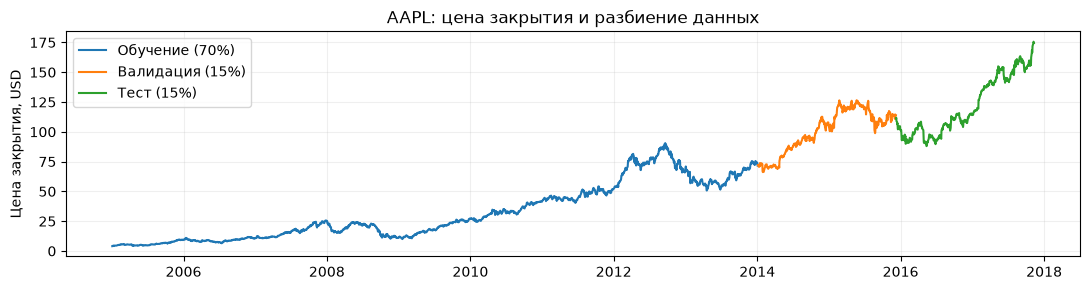

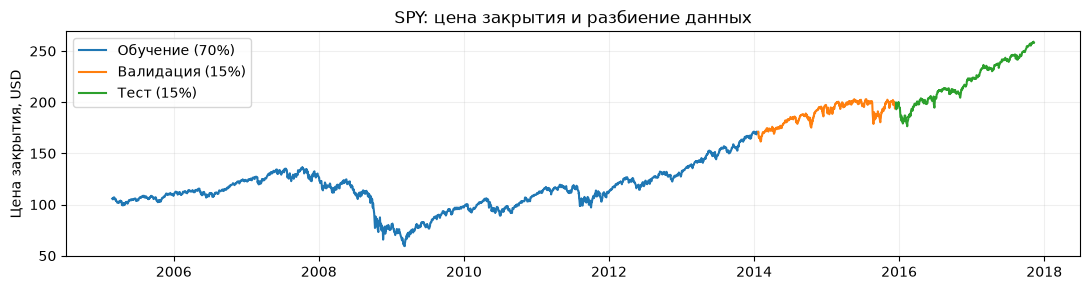

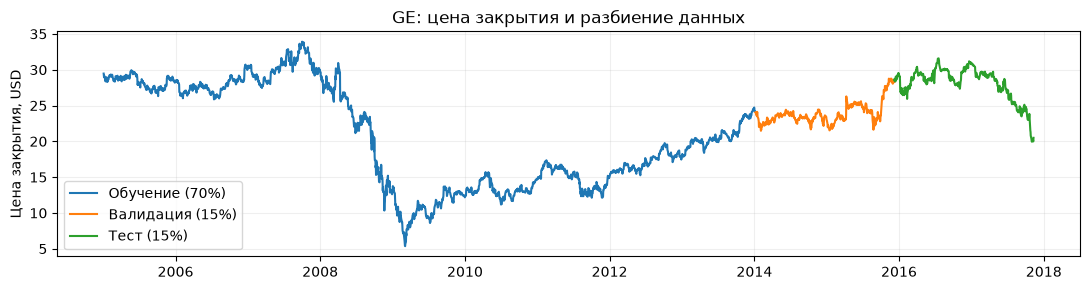

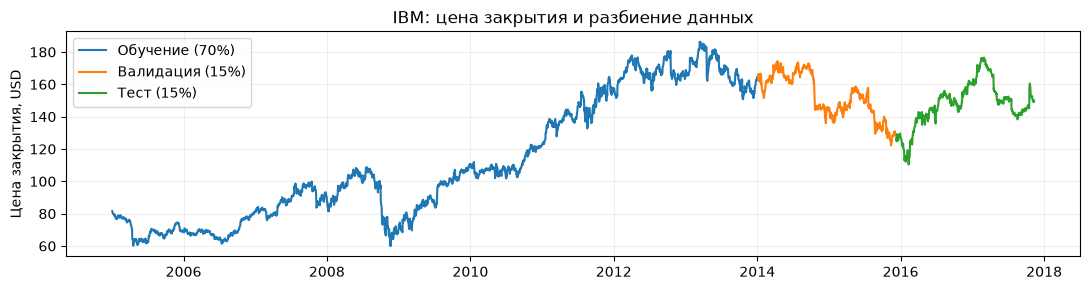

In [5]:
import matplotlib.pyplot as plt

for stock in stocks:
    df = tables[stock]
    train_end = int(len(df) * 0.7)
    val_end = int(len(df) * 0.85)

    plt.figure(figsize=(11, 3))
    plt.plot(df["Date"].iloc[:train_end], df["Close"].iloc[:train_end], label="Обучение (70%)")
    plt.plot(df["Date"].iloc[train_end:val_end], df["Close"].iloc[train_end:val_end], label="Валидация (15%)")
    plt.plot(df["Date"].iloc[val_end:], df["Close"].iloc[val_end:], label="Тест (15%)")
    plt.title(stock + ": цена закрытия и разбиение данных")
    plt.ylabel("Цена закрытия, USD")
    plt.grid(alpha=0.2)
    plt.legend()
    plt.tight_layout()
    plt.show()

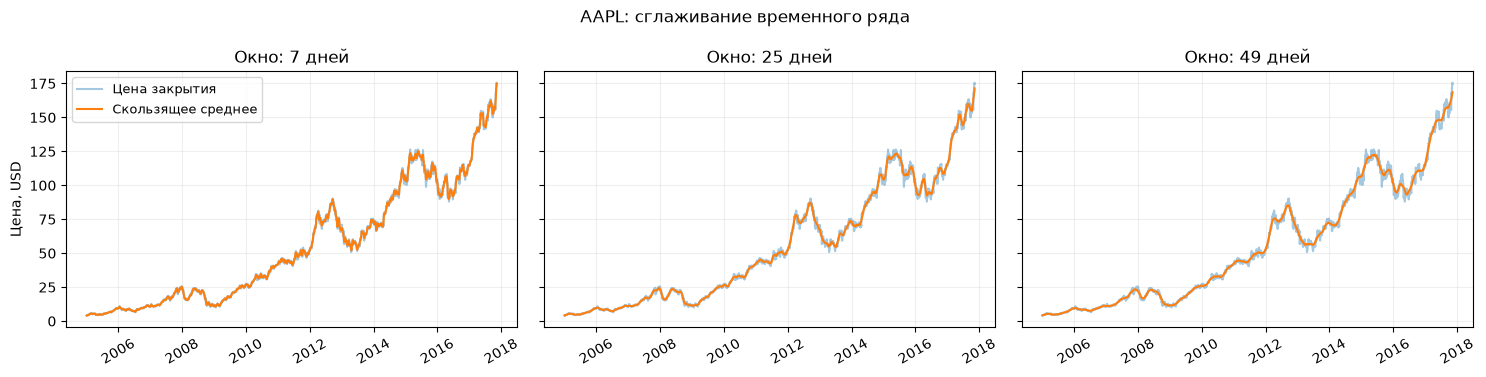

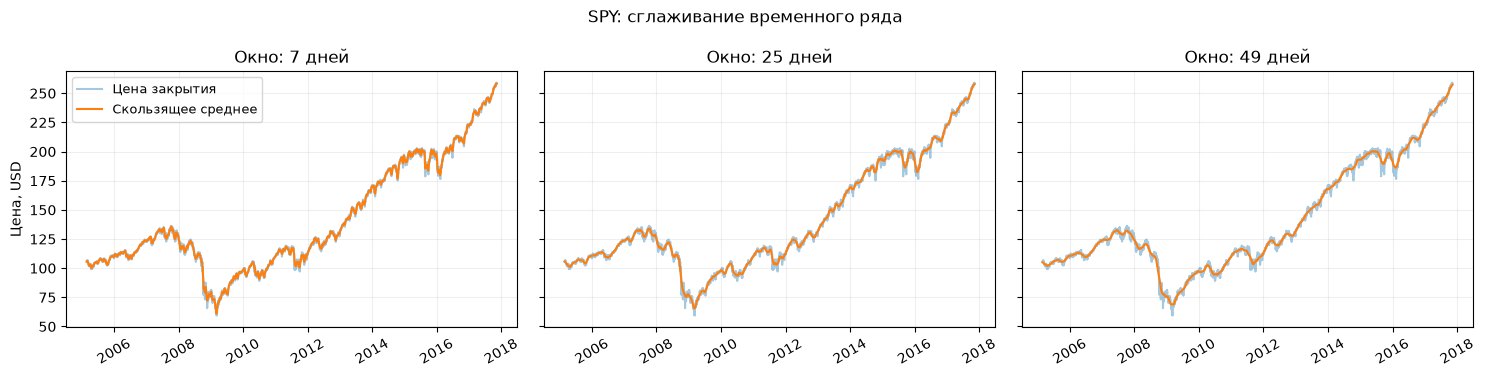

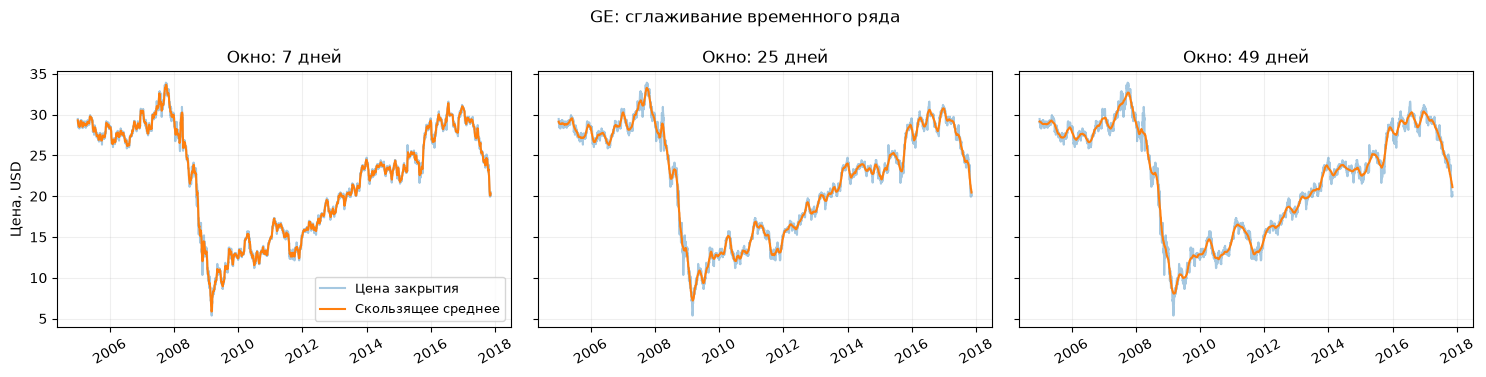

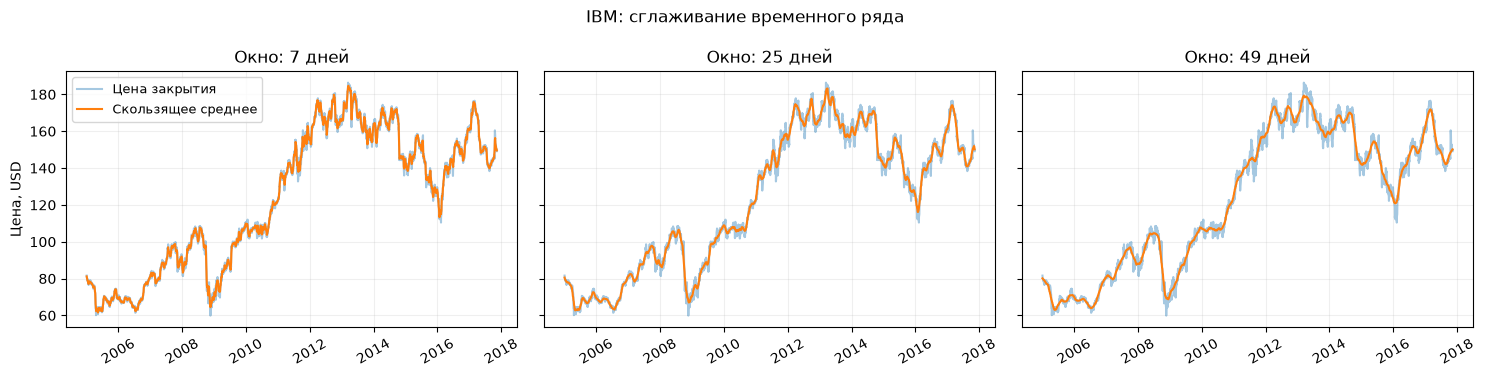

In [6]:
from torch.nn import functional as F

close_index = features.index("Close")

def moving_average(history, window):
    history = history.transpose(1, 2)
    pad = (window - 1) // 2
    history = F.pad(history, (pad, pad), mode="replicate")
    trend = F.avg_pool1d(history, window, stride=1)
    return trend.transpose(1, 2)


for stock in stocks:
    df = tables[stock]
    values = torch.tensor(df["Close"].values, dtype=torch.float32)
    values = values.reshape(1, -1, 1)

    fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharex=True, sharey=True)
    for ax, window in zip(axes, [7, 25, 49]):
        trend = moving_average(values, window)
        ax.plot(df["Date"], df["Close"], alpha=0.4, label="Цена закрытия")
        ax.plot(df["Date"], trend[0, :, 0], label="Скользящее среднее")
        ax.set_title("Окно: " + str(window) + " дней")
        ax.grid(alpha=0.2)
        ax.tick_params(axis="x", labelrotation=30)

    axes[0].set_ylabel("Цена, USD")
    axes[0].legend(fontsize=9)
    fig.suptitle(stock + ": сглаживание временного ряда")
    plt.tight_layout()
    plt.show()

## LSTM

In [7]:
from torch import nn


def normalize(X):
    mean = X.mean(dim=1, keepdim=True).detach()
    std = torch.sqrt(X.var(dim=1, keepdim=True, unbiased=False) + 0.00001).detach()
    X = (X - mean) / std
    return X, mean, std


class LSTMForecast(nn.Module):
    def __init__(self, channels, horizon, hidden_size=32):
        super().__init__()
        self.channels = channels
        self.horizon = horizon
        self.lstm = nn.LSTM(channels, hidden_size, batch_first=True)
        self.linear = nn.Linear(hidden_size, horizon * channels)

    def forward(self, X):
        X, mean, std = normalize(X)
        states, _ = self.lstm(X)
        y = self.linear(states[:, -1])
        y = y.reshape(-1, self.horizon, self.channels)
        return y * std + mean

## sLSTM

In [8]:
def slstm_step(gates, weight, h, c, n, m):
    z, i, f, o = (gates + F.linear(h, weight)).chunk(4, dim=1)

    z = torch.tanh(z)
    o = torch.sigmoid(o)
    log_f = F.logsigmoid(f)

    new_m = torch.maximum(log_f + m, i)
    i = torch.exp(i - new_m)
    f = torch.exp(log_f + m - new_m)

    c = f * c + i * z
    n = f * n + i
    h = o * c / (n + 0.000001)

    return h, c, n, new_m


def slstm_block(inputs, weight, h, c, n, m):
    for gates in inputs.unbind(0):
        h, c, n, m = slstm_step(gates, weight, h, c, n, m)
    return h, c, n, m


class SLSTM(nn.Module):
    def __init__(self, hidden_size, input_size=None, return_sequence=True):
        super().__init__()
        self.hidden_size = hidden_size
        self.return_sequence = return_sequence

        if input_size is None:
            input_size = hidden_size

        self.input_weights = nn.Linear(input_size, 4 * hidden_size)
        self.recurrent_weights = nn.Linear(hidden_size, 4 * hidden_size, bias=False)

    def forward(self, X):
        h = X.new_zeros((X.shape[0], self.hidden_size))
        c = torch.zeros_like(h)
        n = torch.zeros_like(h)
        m = torch.zeros_like(h)

        inputs = self.input_weights(X).transpose(0, 1).contiguous()
        weight = self.recurrent_weights.weight

        if self.return_sequence:
            states = []
            for gates in inputs.unbind(0):
                h, c, n, m = slstm_step(gates, weight, h, c, n, m)
                states.append(h)
            return torch.stack(states, dim=1)

        block = torch.compile(slstm_block, dynamic=True)

        for part in inputs.split(10):
            h, c, n, m = block(part, weight, h, c, n, m)

        return h

In [9]:
class SLSTMForecast(nn.Module):
    def __init__(self, channels, horizon, hidden_size=32):
        super().__init__()
        self.channels = channels
        self.horizon = horizon
        self.lstm = SLSTM(hidden_size, channels, return_sequence=False)
        self.linear = nn.Linear(hidden_size, horizon * channels)

    def forward(self, X):
        X, mean, std = normalize(X)
        last = self.lstm(X)
        y = self.linear(last)
        y = y.reshape(-1, self.horizon, self.channels)
        return y * std + mean

## xLSTMTime

In [10]:
class XLSTMTimeForecast(nn.Module):
    def __init__(
            self,
            history_size,
            horizon,
            hidden_size=32,
            window=25,
            cell="slstm"
    ):
        super().__init__()
        self.window = window
        self.cell = cell

        self.trend_layer = nn.Linear(history_size, horizon)
        self.residual_layer = nn.Linear(history_size, horizon)
        self.to_hidden = nn.Linear(horizon, hidden_size)

        self.memory_norm = nn.LayerNorm(hidden_size)
        if cell == "slstm":
            self.memory = SLSTM(hidden_size)
        else:
            self.memory = nn.LSTM(hidden_size, hidden_size, batch_first=True)

        self.feedforward_norm = nn.LayerNorm(hidden_size)
        self.feedforward = nn.Sequential(
            nn.Linear(hidden_size, 2 * hidden_size),
            nn.GELU(),
            nn.Linear(2 * hidden_size, hidden_size)
        )
        self.to_forecast = nn.Linear(hidden_size, horizon)

    def forward(self, X):
        X, mean, std = normalize(X)

        if self.window is None:
            trend = X / 2
            residual = X / 2
        else:
            trend = moving_average(X, self.window)
            residual = X - trend

        trend = self.trend_layer(trend.transpose(1, 2))
        residual = self.residual_layer(residual.transpose(1, 2))
        X = self.to_hidden(trend + residual)

        memory_input = self.memory_norm(X)
        if self.cell == "slstm":
            memory_output = self.memory(memory_input)
        else:
            memory_output, _ = self.memory(memory_input)

        X = X + memory_output
        X = X + self.feedforward(self.feedforward_norm(X))
        y = self.to_forecast(X)
        y = y.transpose(1, 2)
        return y * std + mean

In [11]:
hidden_size = 32

def make_model(name, horizon, window=25, cell="slstm"):
    if name == "LSTM":
        return LSTMForecast(len(features), horizon, hidden_size)
    if name == "sLSTM":
        return SLSTMForecast(len(features), horizon, hidden_size)
    if name == "xLSTMTime":
        return XLSTMTimeForecast(lookback, horizon, hidden_size, window, cell)


def count_parameters(model):
    count = 0
    for p in model.parameters():
        count += p.numel()
    return count

In [12]:
batch_size = 256


def batches(dataset, generator=None):
    X, y = dataset.tensors

    if generator is None:
        for start in range(0, len(X), batch_size):
            end = start + batch_size
            yield X[start:end], y[start:end]
    else:
        order = torch.randperm(len(X), device=device, generator=generator)
        for ids in order.split(batch_size):
            yield X[ids], y[ids]


def calculate_metrics(model, dataset):
    if model is not None:
        model.eval()

    errors = []

    with torch.no_grad():
        for X, y in batches(dataset):
            if model is None:
                preds = X[:, -1:, :].expand_as(y)
            else:
                preds = model(X)

            errors.append(preds - y)

    error = torch.cat(errors)
    close_error = error[:, :, close_index]

    mse = (error ** 2).mean().item()
    mae = error.abs().mean().item()
    close_mse = (close_error ** 2).mean().item()
    close_mae = close_error.abs().mean().item()

    return mse, mae, close_mse, close_mae

In [13]:
import copy
import time

learning_rate = 0.001
epochs = 30
patience = 4


def train_model(model, train_data, val_data, seed, close_only=False):
    model = model.to(device)
    generator = torch.Generator(device=device)
    generator.manual_seed(seed)
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate, fused=(device == "cuda"))
    loss_fn = nn.MSELoss()

    best_close = float("inf")
    best_mse = float("inf")
    best_weights = copy.deepcopy(model.state_dict())
    bad_epochs = 0
    history = []

    if device == "cuda":
        torch.cuda.synchronize()
    start = time.perf_counter()

    for epoch in range(1, epochs + 1):
        model.train()
        train_loss = torch.zeros((), device=device)

        for X, y in batches(train_data, generator):
            optimizer.zero_grad(set_to_none=True)
            preds = model(X)

            if close_only:
                loss = loss_fn(preds[:, :, close_index], y[:, :, close_index])
            else:
                loss = loss_fn(preds, y)

            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()

            train_loss += loss.detach() * len(X)

        train_loss = train_loss.item() / len(train_data)
        val_mse, _, val_close_mse, _ = calculate_metrics(model, val_data)

        history.append({
            "epoch": epoch,
            "train_mse": train_loss,
            "val_mse": val_mse,
            "val_close_mse": val_close_mse
        })

        if val_close_mse < best_close - 0.000001:
            best_close = val_close_mse
            best_mse = val_mse
            best_weights = copy.deepcopy(model.state_dict())
            bad_epochs = 0
        else:
            bad_epochs += 1

        if bad_epochs >= patience:
            break

    if device == "cuda":
        torch.cuda.synchronize()
    seconds = time.perf_counter() - start

    model.load_state_dict(best_weights)
    return model, history, best_mse, best_close, seconds

In [14]:
def run_model(stock, horizon, name, seed, train, val, test,
              window=25, cell="slstm", close_only=False):
    torch.manual_seed(seed)
    model = make_model(name, horizon, window, cell)

    model, history, val_mse, val_close_mse, seconds = train_model(
        model, train, val, seed, close_only
    )

    mse, mae, close_mse, close_mae = calculate_metrics(model, test)

    row = {
        "dataset": stock,
        "horizon": horizon,
        "model": name,
        "seed": seed,
        "MSE": mse,
        "MAE": mae,
        "Close_MSE": close_mse,
        "Close_MAE": close_mae,
        "val_MSE": val_mse,
        "val_Close_MSE": val_close_mse,
        "parameters": count_parameters(model),
        "epochs": len(history),
        "train_seconds": seconds,
        "seconds_per_epoch": seconds / len(history)
    }

    return row, model, history


def summarize_runs(runs, keys):
    groups = runs.drop(columns="seed").groupby(keys)
    mean = groups.mean(numeric_only=True)
    std = groups.std(numeric_only=True).add_suffix("_std")

    result = pd.concat([mean, std], axis=1)
    result["n_runs"] = groups.size()
    return result.reset_index()

## Эксперимент 1

Обучим LSTM, sLSTM и xLSTMTime на различных горизонтах и посмотрим, дает ли более сложная архитектура преимущество

In [15]:
horizons = [5, 20, 60]
seeds = [1, 2, 3]
models = ["LSTM", "sLSTM", "xLSTMTime"]

results = []
forecasts = {}
forecast_truth = {}
forecast_dates = {}
training_histories = {}

for stock in stocks:
    print(stock)
    for horizon in horizons:
        train, val, test, scaler = prepare_data(stock, horizon)

        mse, mae, close_mse, close_mae = calculate_metrics(None, test)
        val_mse, _, val_close_mse, _ = calculate_metrics(None, val)
        results.append({
            "dataset": stock,
            "horizon": horizon,
            "model": "Naive",
            "seed": None,
            "MSE": mse,
            "MAE": mae,
            "Close_MSE": close_mse,
            "Close_MAE": close_mae,
            "val_MSE": val_mse,
            "val_Close_MSE": val_close_mse,
            "parameters": 0,
            "epochs": 0,
            "train_seconds": 0,
            "seconds_per_epoch": np.nan
        })

        X, y = test.tensors
        scale = scaler.scale_[close_index]
        mean = scaler.mean_[close_index]
        forecast_truth[stock, horizon] = y[:, -1, close_index].cpu().numpy() * scale + mean
        forecasts[stock, horizon, "Naive"] = X[:, -1, close_index].cpu().numpy() * scale + mean

        df = tables[stock]
        val_end = int(len(df) * 0.85)
        forecast_dates[stock, horizon] = df["Date"].iloc[max(val_end, lookback) + horizon - 1:]

        for seed in seeds:
            for name in models:
                row, model, history = run_model(stock, horizon, name, seed,
                                                train, val, test)
                seconds = round(row["seconds_per_epoch"], 2)
                print(stock, horizon, seed, name, seconds, "с/эпоху", flush=True)
                results.append(row)
                training_histories[stock, horizon, name, seed] = history

                predictions = []
                model.eval()
                with torch.no_grad():
                    for X, y in batches(test):
                        preds = model(X)
                        predictions.extend(preds[:, -1, close_index].cpu().numpy())

                forecasts[stock, horizon, name, seed] = np.array(predictions) * scale + mean

results_runs = pd.DataFrame(results)
results_df = summarize_runs(results_runs, ["dataset", "horizon", "model"])

AAPL
AAPL 5 1 LSTM 0.05 с/эпоху
AAPL 5 1 sLSTM 2.03 с/эпоху
AAPL 5 1 xLSTMTime 0.16 с/эпоху
AAPL 5 2 LSTM 0.04 с/эпоху
AAPL 5 2 sLSTM 0.65 с/эпоху
AAPL 5 2 xLSTMTime 0.15 с/эпоху
AAPL 5 3 LSTM 0.04 с/эпоху
AAPL 5 3 sLSTM 0.64 с/эпоху
AAPL 5 3 xLSTMTime 0.14 с/эпоху
AAPL 20 1 LSTM 0.04 с/эпоху
AAPL 20 1 sLSTM 0.67 с/эпоху
AAPL 20 1 xLSTMTime 0.15 с/эпоху
AAPL 20 2 LSTM 0.04 с/эпоху
AAPL 20 2 sLSTM 0.68 с/эпоху
AAPL 20 2 xLSTMTime 0.16 с/эпоху
AAPL 20 3 LSTM 0.04 с/эпоху
AAPL 20 3 sLSTM 0.68 с/эпоху
AAPL 20 3 xLSTMTime 0.16 с/эпоху
AAPL 60 1 LSTM 0.04 с/эпоху
AAPL 60 1 sLSTM 0.65 с/эпоху
AAPL 60 1 xLSTMTime 0.15 с/эпоху
AAPL 60 2 LSTM 0.04 с/эпоху
AAPL 60 2 sLSTM 0.64 с/эпоху
AAPL 60 2 xLSTMTime 0.14 с/эпоху
AAPL 60 3 LSTM 0.04 с/эпоху
AAPL 60 3 sLSTM 0.68 с/эпоху
AAPL 60 3 xLSTMTime 0.15 с/эпоху
SPY
SPY 5 1 LSTM 0.04 с/эпоху
SPY 5 1 sLSTM 0.64 с/эпоху
SPY 5 1 xLSTMTime 0.15 с/эпоху
SPY 5 2 LSTM 0.04 с/эпоху
SPY 5 2 sLSTM 0.65 с/эпоху
SPY 5 2 xLSTMTime 0.15 с/эпоху
SPY 5 3 LSTM 0.04 с/эп

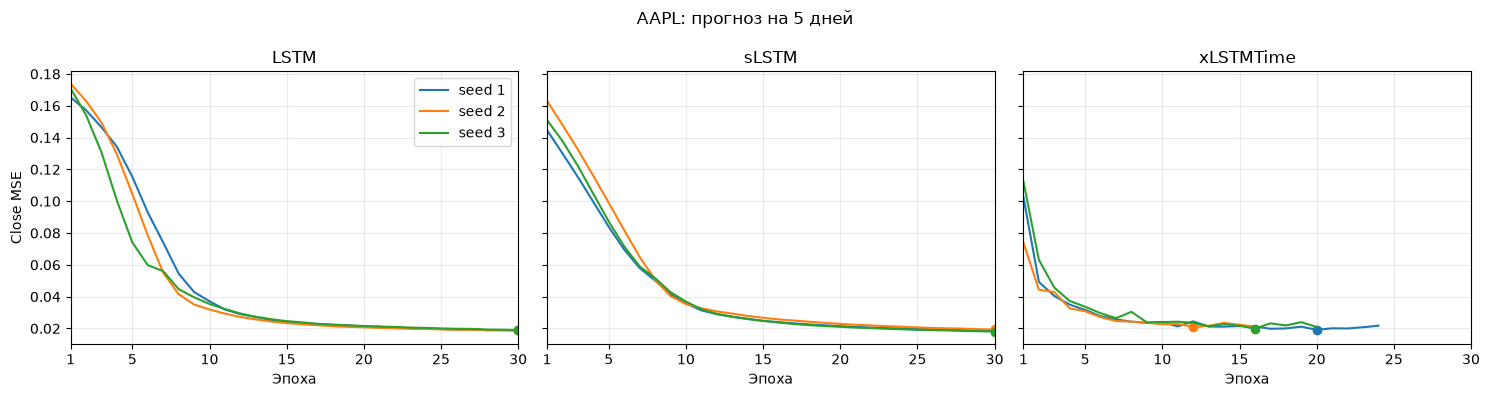

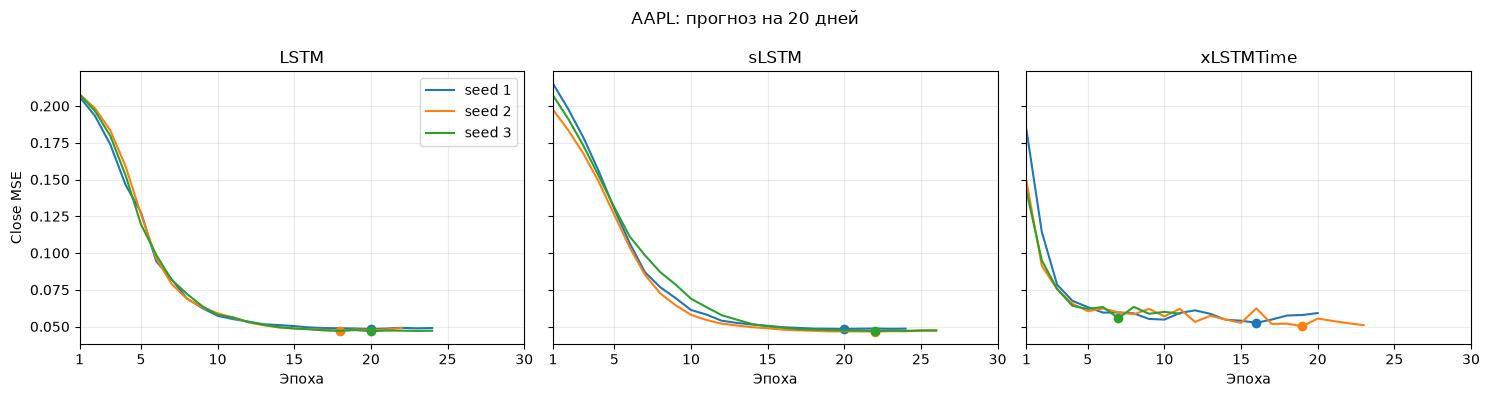

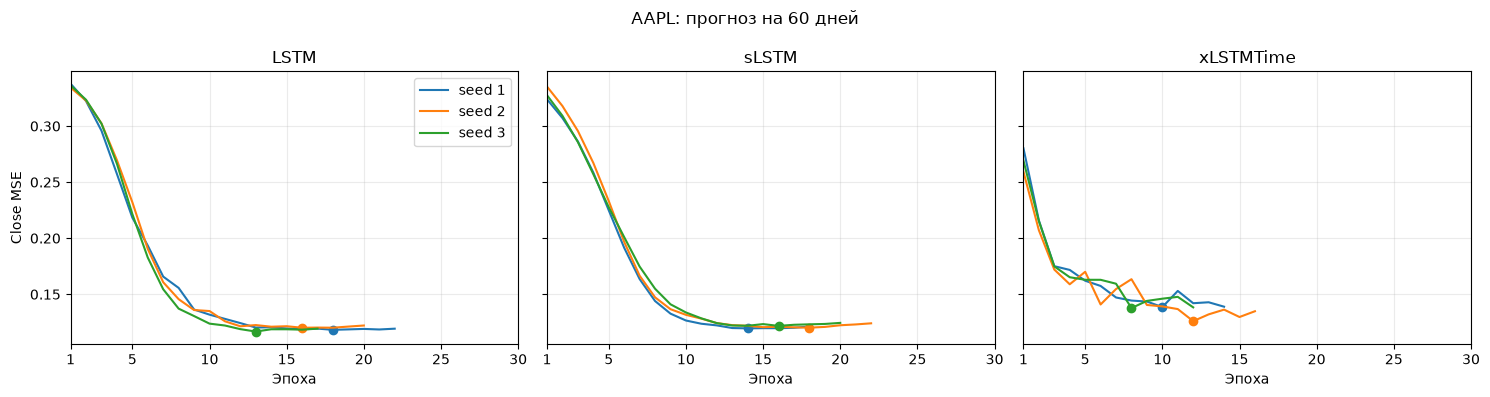

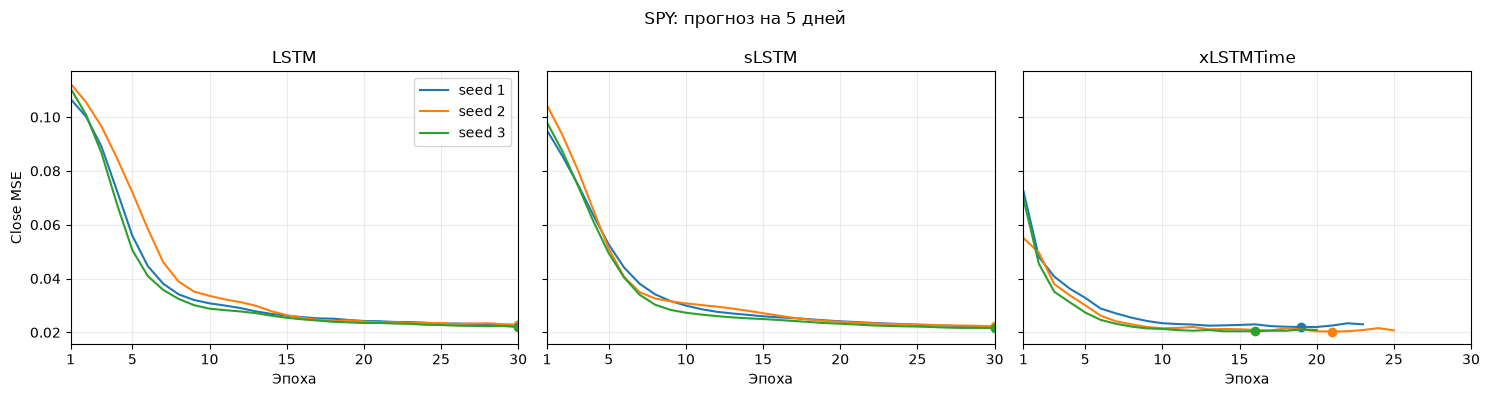

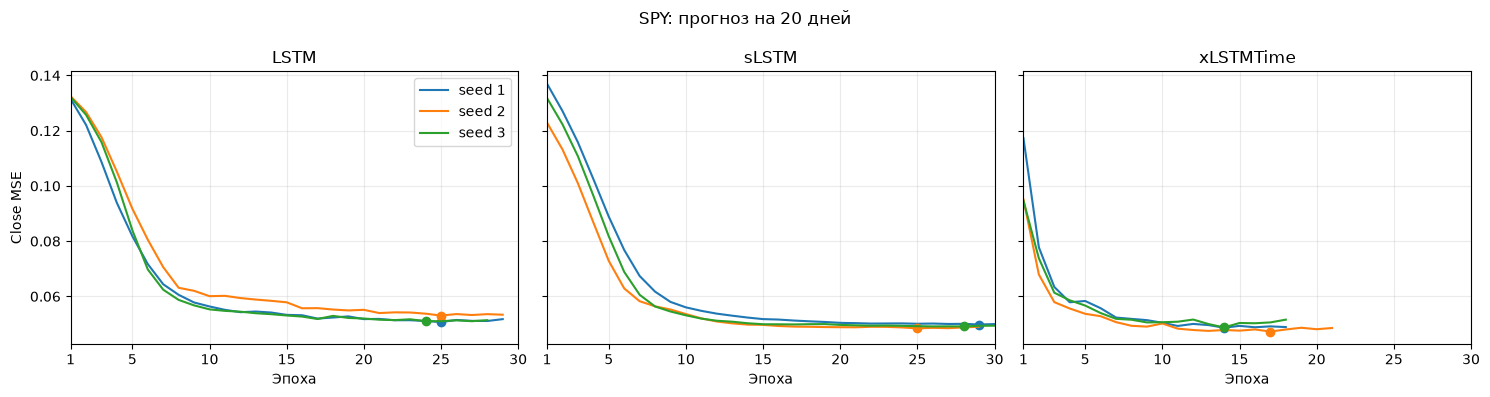

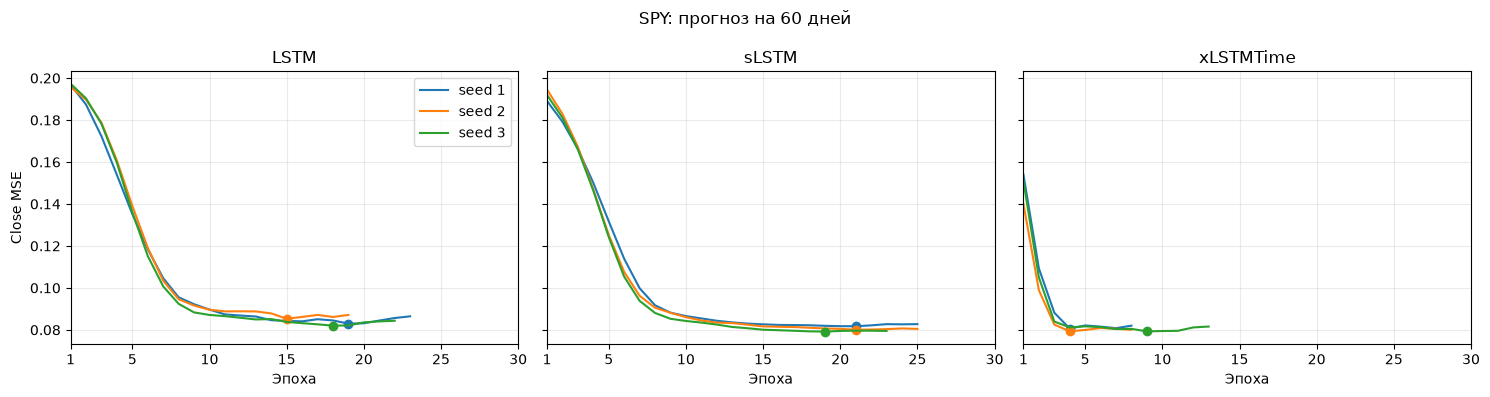

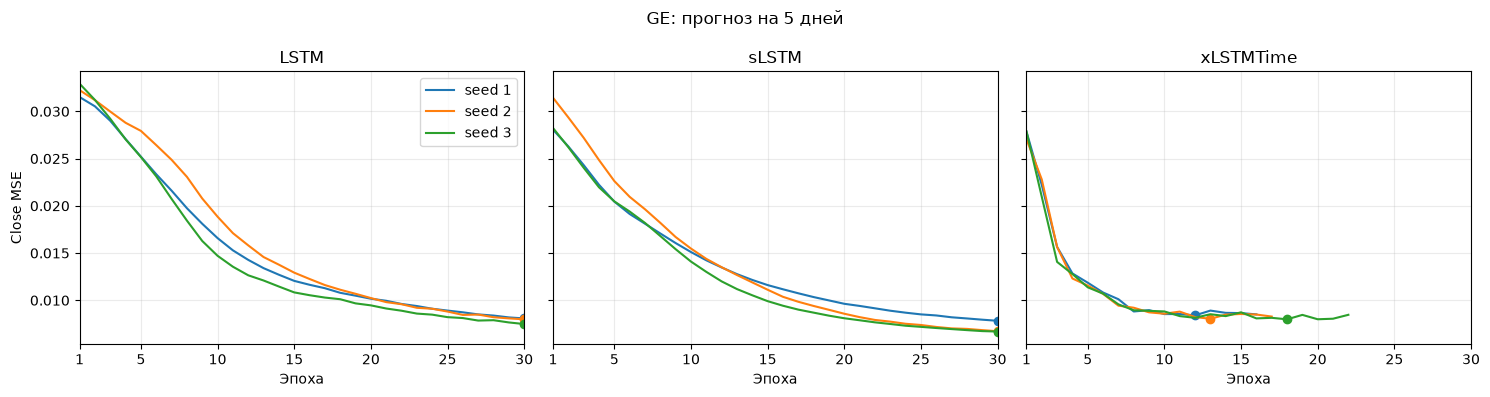

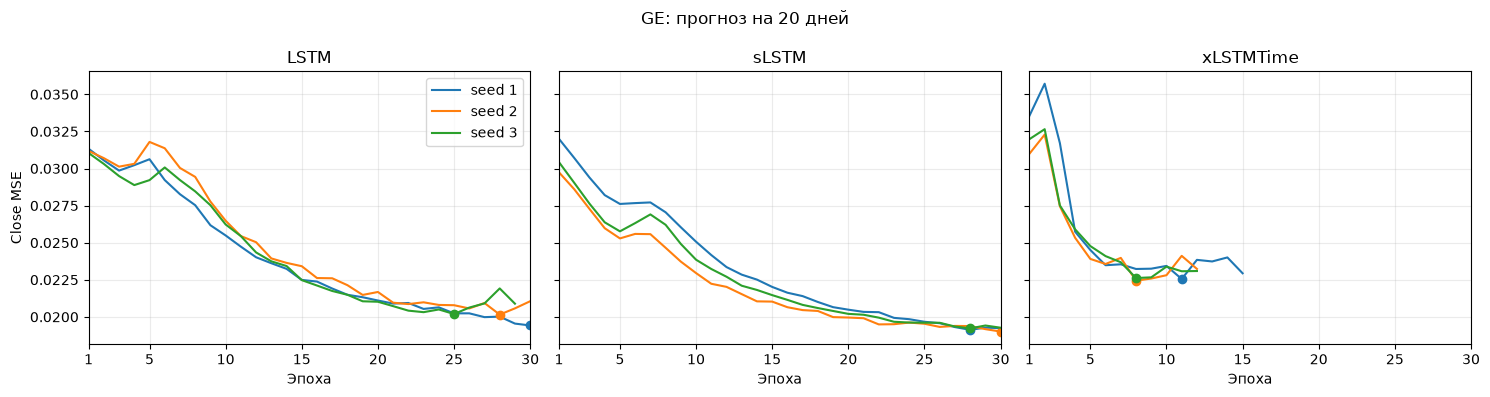

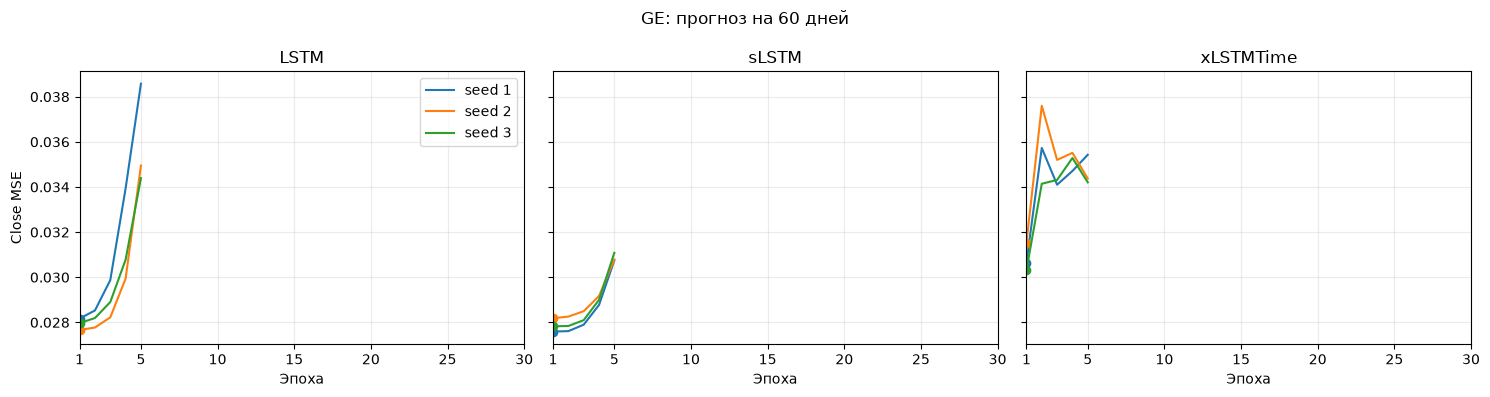

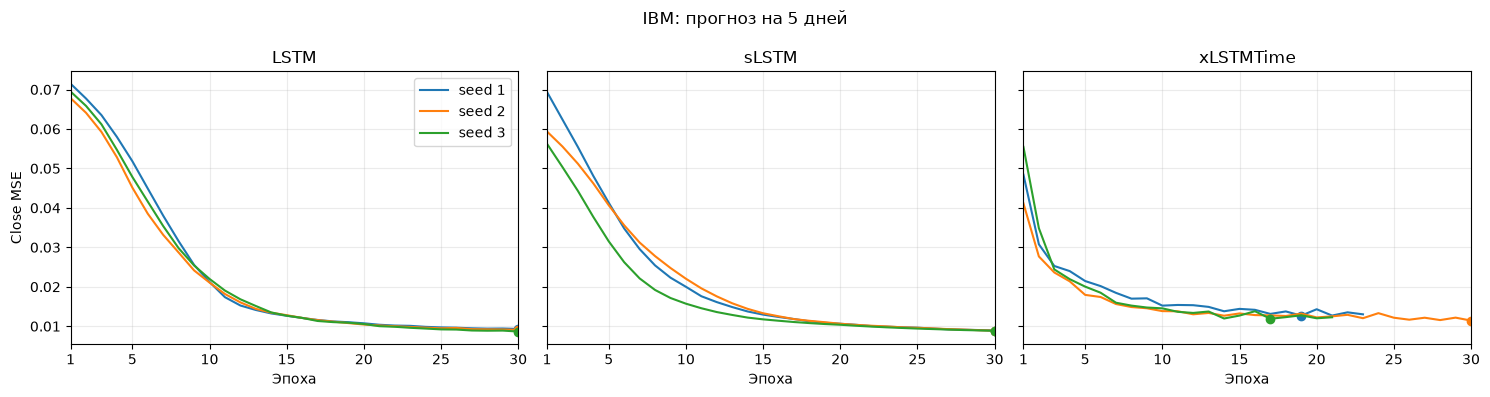

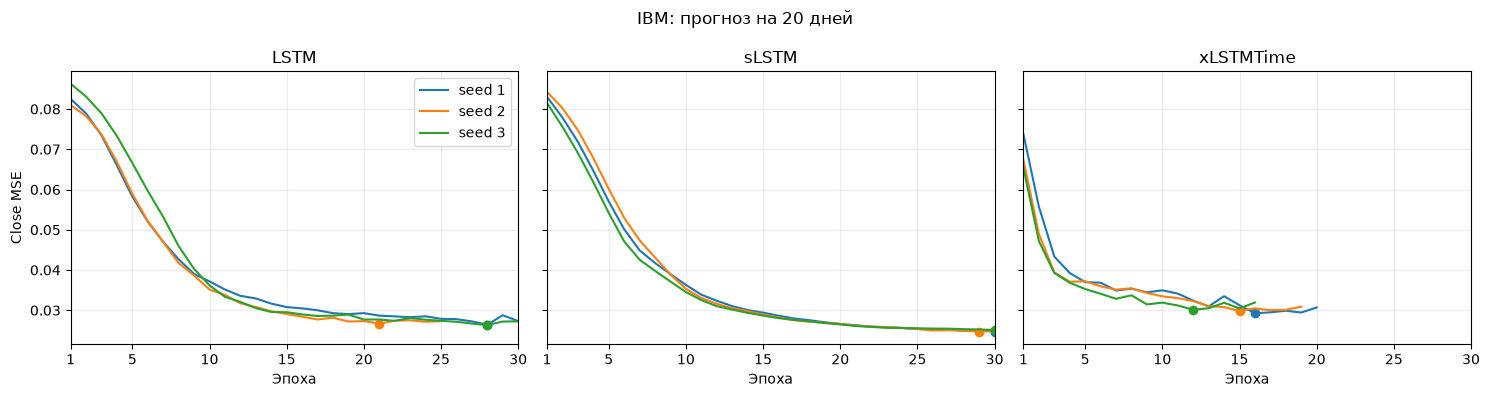

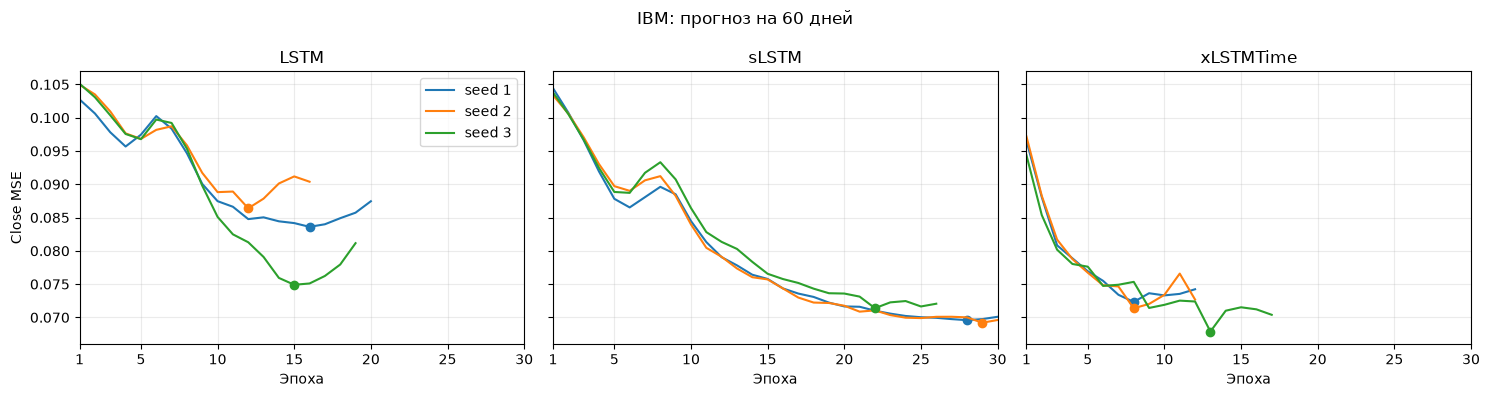

In [32]:
for stock in stocks:
    for horizon in horizons:
        fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True, sharey=True)

        for ax, name in zip(axes, models):
            for seed in seeds:
                history = pd.DataFrame(training_histories[stock, horizon, name, seed])
                ax.plot(history["epoch"], history["val_close_mse"], label="seed " + str(seed))

                best = history["val_close_mse"].idxmin()
                ax.plot(history.loc[best, "epoch"], history.loc[best, "val_close_mse"],
                        marker="o", color=ax.lines[-1].get_color())

            ax.set_title(name)
            ax.set_xlabel("Эпоха")
            ax.set_xticks([1, 5, 10, 15, 20, 25, 30])
            ax.set_xlim(1, epochs)
            ax.grid(alpha=0.25)

        axes[0].set_ylabel("Close MSE")
        axes[0].legend()

        fig.suptitle(f"{stock}: прогноз на {horizon} дней")
        plt.tight_layout()
        plt.show()

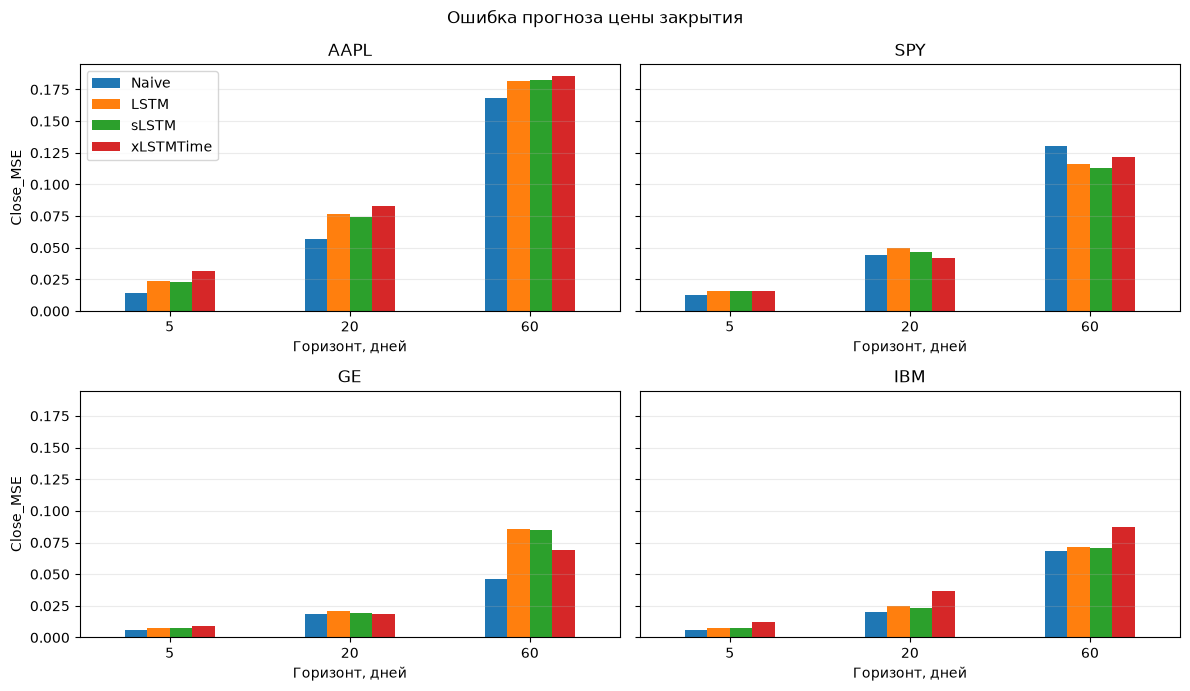

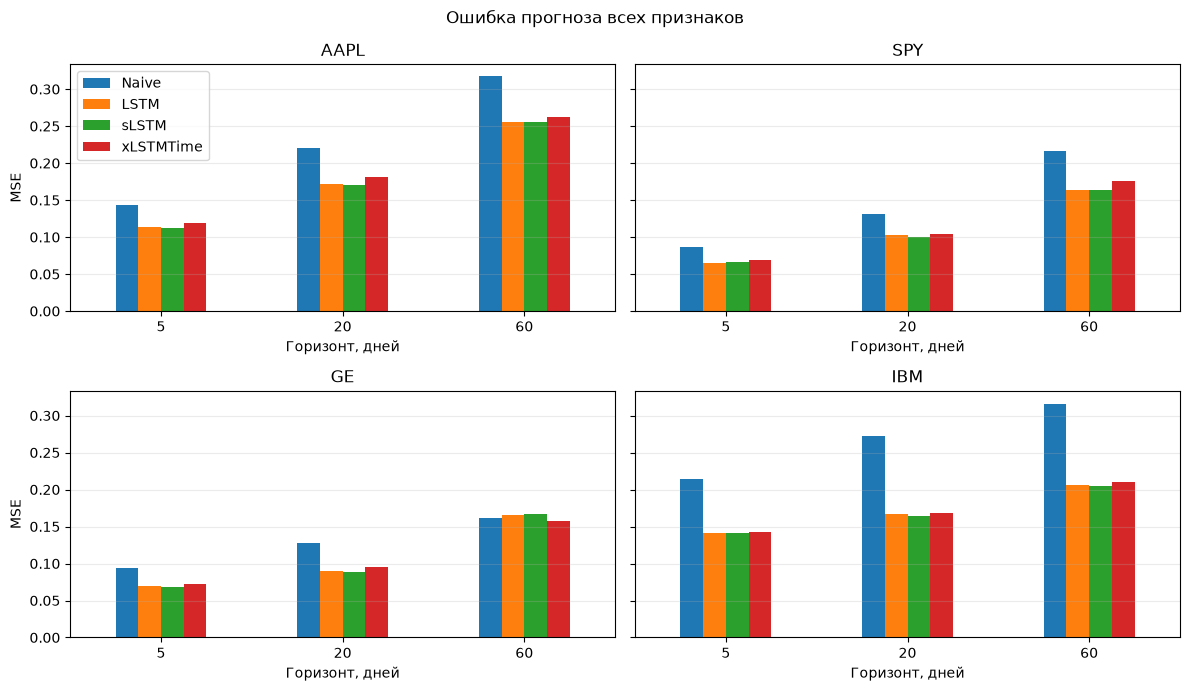

In [33]:
keys = ["dataset", "horizon"]

for metric in ["Close_MSE", "MSE"]:
    scores = results_df.pivot(index=keys, columns="model", values=metric)

    fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharey=True)

    for ax, stock in zip(axes.flat, stocks):
        scores.loc[stock].reindex(horizons)[["Naive"] + models].plot.bar(
            ax=ax, rot=0, legend=False
        )

        ax.set_title(stock)
        ax.set_xlabel("Горизонт, дней")
        ax.set_ylabel(metric)
        ax.grid(axis="y", alpha=0.25)

    axes[0, 0].legend()

    if metric == "Close_MSE":
        title = "Ошибка прогноза цены закрытия"
    else:
        title = "Ошибка прогноза всех признаков"

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

In [34]:
close_means = results_df.pivot(index=keys, columns="model", values="Close_MSE")

winners = close_means.idxmin(axis=1)
display(winners.unstack("horizon"))


close_std = results_runs.groupby(keys + ["model"])["Close_MSE"].std()
close_std = close_std.unstack("model").reindex(close_means.index)

table = pd.DataFrame(index=close_means.index)
table["Naive"] = close_means["Naive"].round(4)

for name in models:
    table[name] = [
        f"{mean:.4f} ± {std:.4f}"
        for mean, std in zip(close_means[name], close_std[name])
    ]

display(table)

horizon,5,20,60
dataset,,,
AAPL,Naive,Naive,Naive
GE,Naive,Naive,Naive
IBM,Naive,Naive,Naive
SPY,Naive,xLSTMTime,sLSTM


Naive             LSTM            sLSTM        xLSTMTime
dataset horizon                                                           
AAPL    5        0.0146  0.0237 ± 0.0032  0.0229 ± 0.0012  0.0313 ± 0.0020
        20       0.0570  0.0764 ± 0.0059  0.0739 ± 0.0038  0.0832 ± 0.0052
        60       0.1682  0.1815 ± 0.0049  0.1824 ± 0.0029  0.1857 ± 0.0176
GE      5        0.0057  0.0073 ± 0.0002  0.0072 ± 0.0002  0.0090 ± 0.0002
        20       0.0187  0.0206 ± 0.0003  0.0191 ± 0.0002  0.0187 ± 0.0008
        60       0.0466  0.0861 ± 0.0003  0.0852 ± 0.0006  0.0693 ± 0.0027
IBM     5        0.0058  0.0076 ± 0.0004  0.0072 ± 0.0001  0.0123 ± 0.0008
        20       0.0199  0.0247 ± 0.0008  0.0231 ± 0.0004  0.0371 ± 0.0014
        60       0.0684  0.0713 ± 0.0005  0.0704 ± 0.0008  0.0871 ± 0.0005
SPY     5        0.0124  0.0161 ± 0.0005  0.0161 ± 0.0004  0.0160 ± 0.0003
        20       0.0440  0.0502 ± 0.0018  0.0464 ± 0.0003  0.0417 ± 0.0014
        60       0.1307  0.1162 ± 0.0003  0.1131 ± 0.0040  0.1216 ± 0.0089

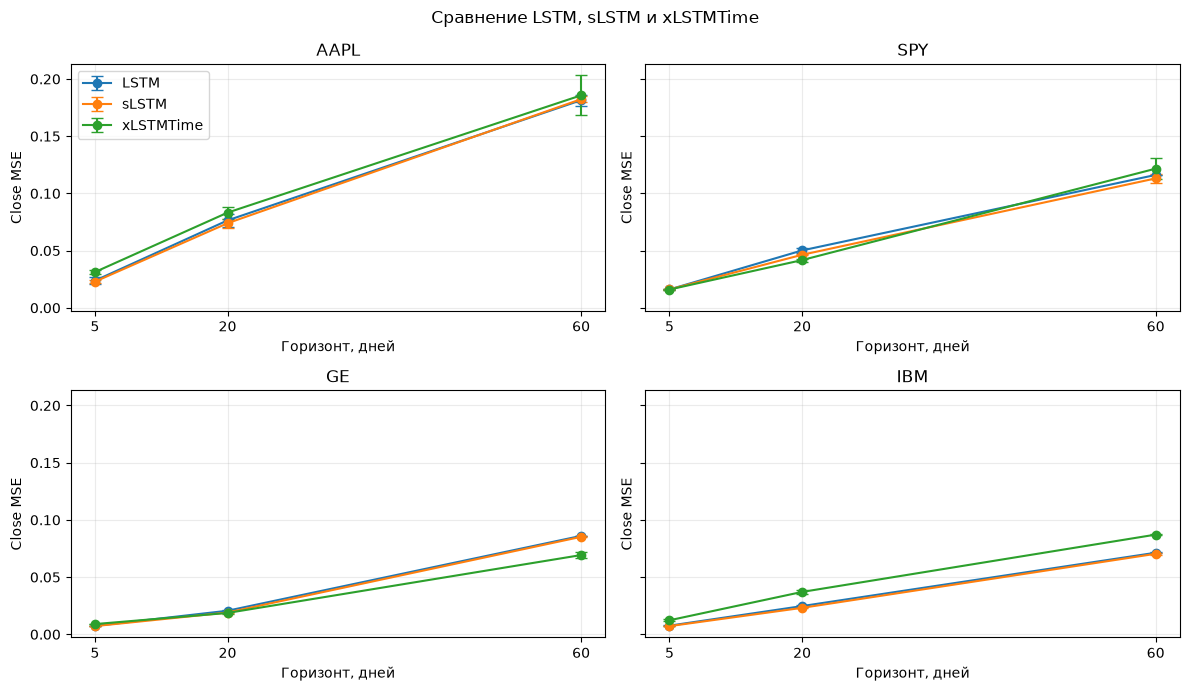

In [35]:
comparison = results_runs[results_runs["model"] != "Naive"]

fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharey=True)

for ax, stock in zip(axes.flat, stocks):
    for name in models:
        scores = comparison[(comparison["dataset"] == stock) &
                            (comparison["model"] == name)]

        mean = scores.groupby("horizon")["Close_MSE"].mean()
        std = scores.groupby("horizon")["Close_MSE"].std()

        ax.errorbar(mean.index, mean, yerr=std,
                    marker="o", capsize=4, label=name)

    ax.set_xticks(horizons)
    ax.set_title(stock)
    ax.set_xlabel("Горизонт, дней")
    ax.set_ylabel("Close MSE")
    ax.grid(alpha=0.25)

axes[0, 0].legend()
fig.suptitle("Сравнение LSTM, sLSTM и xLSTMTime")
plt.tight_layout()
plt.show()

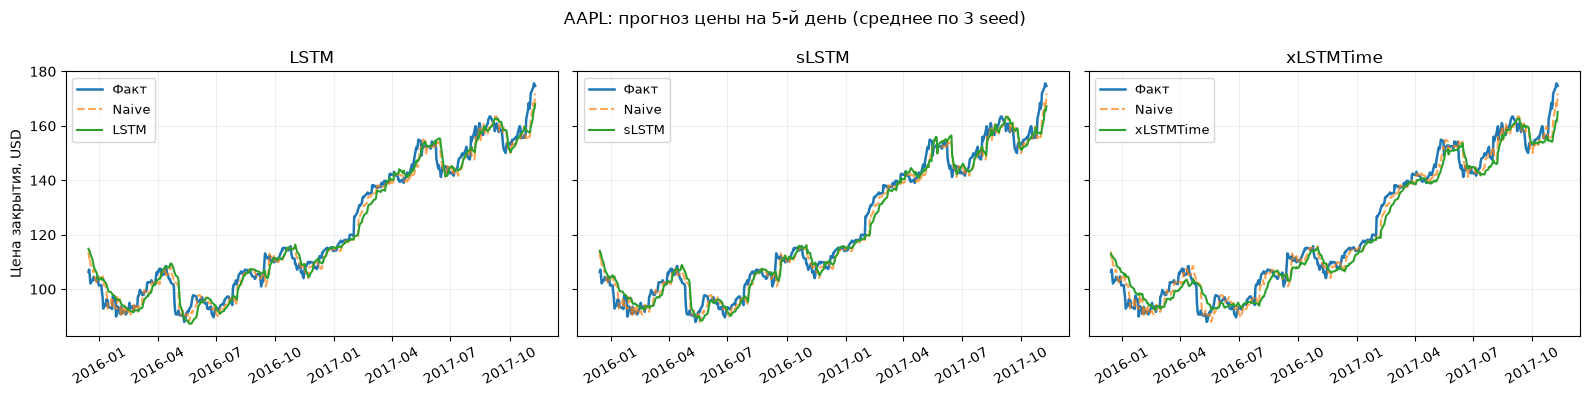

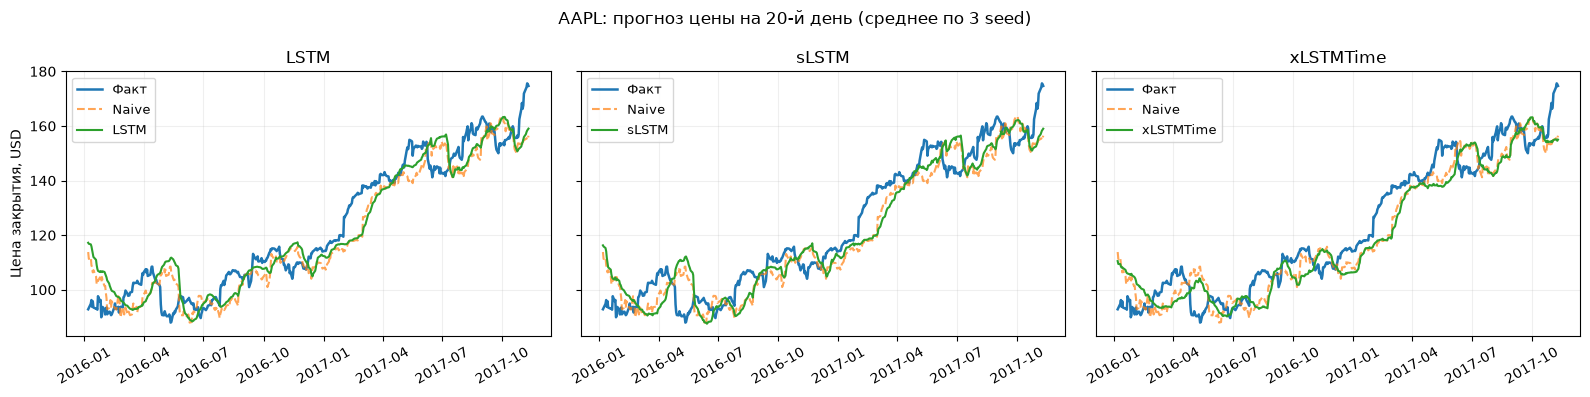

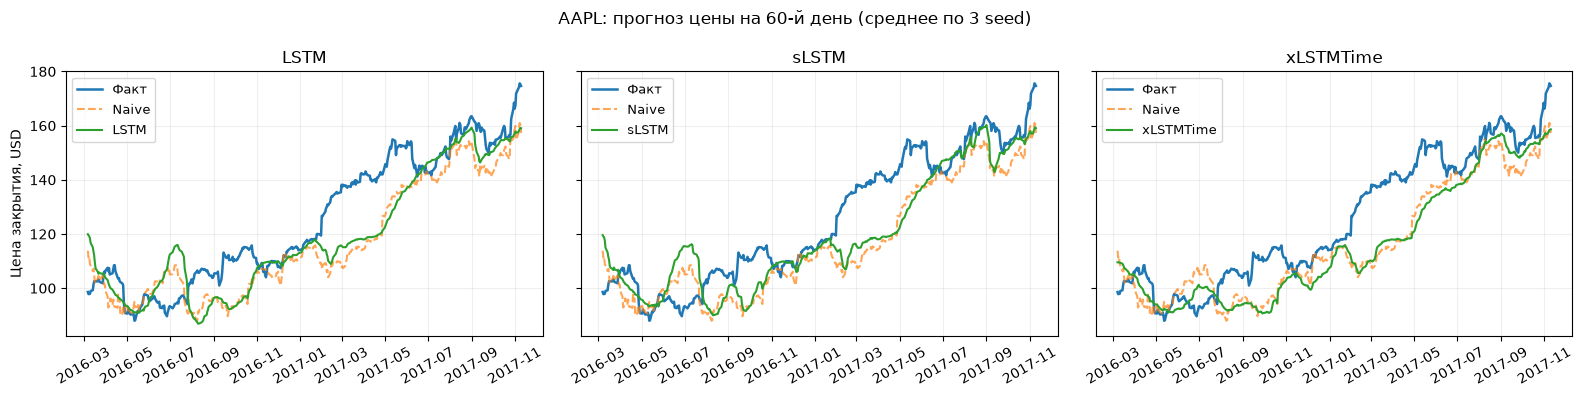

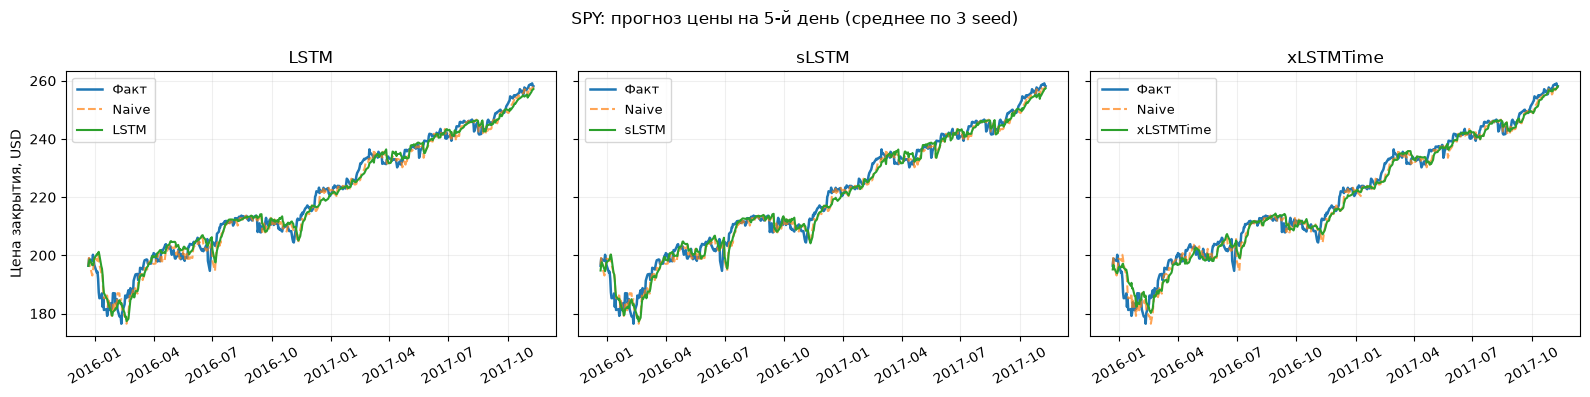

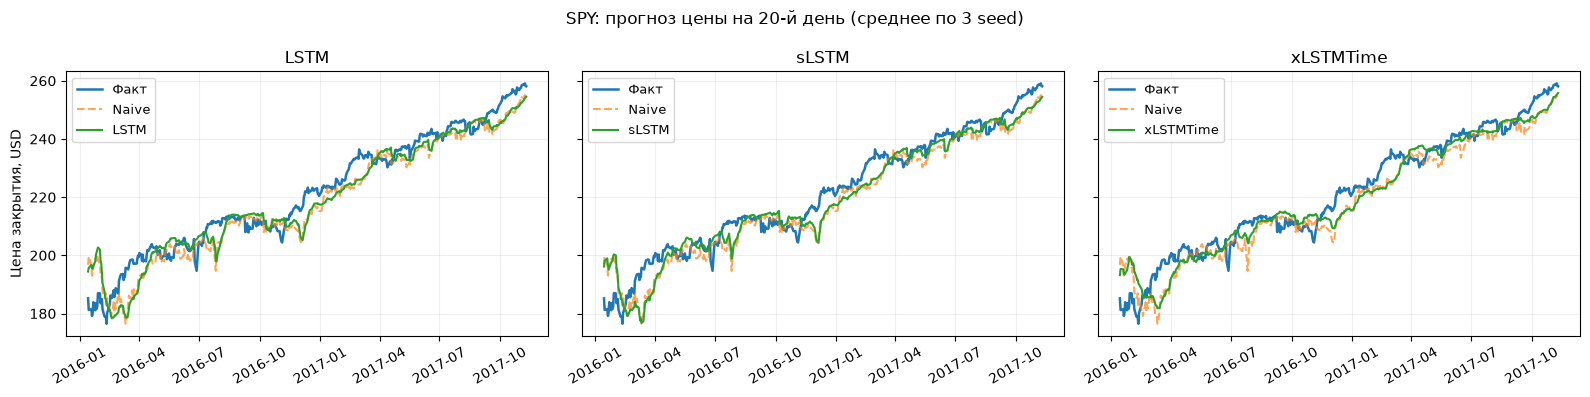

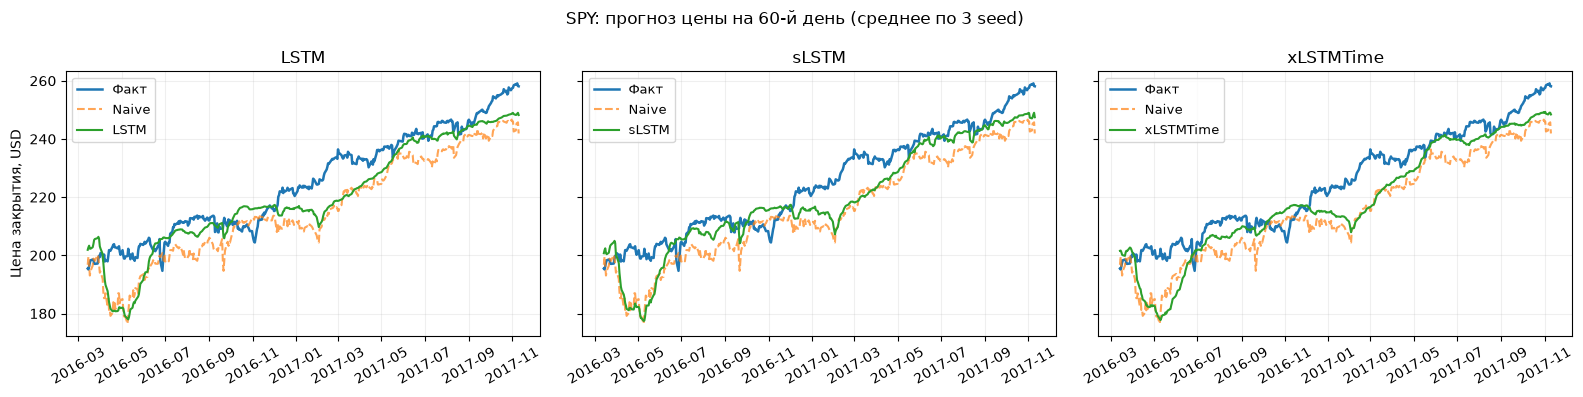

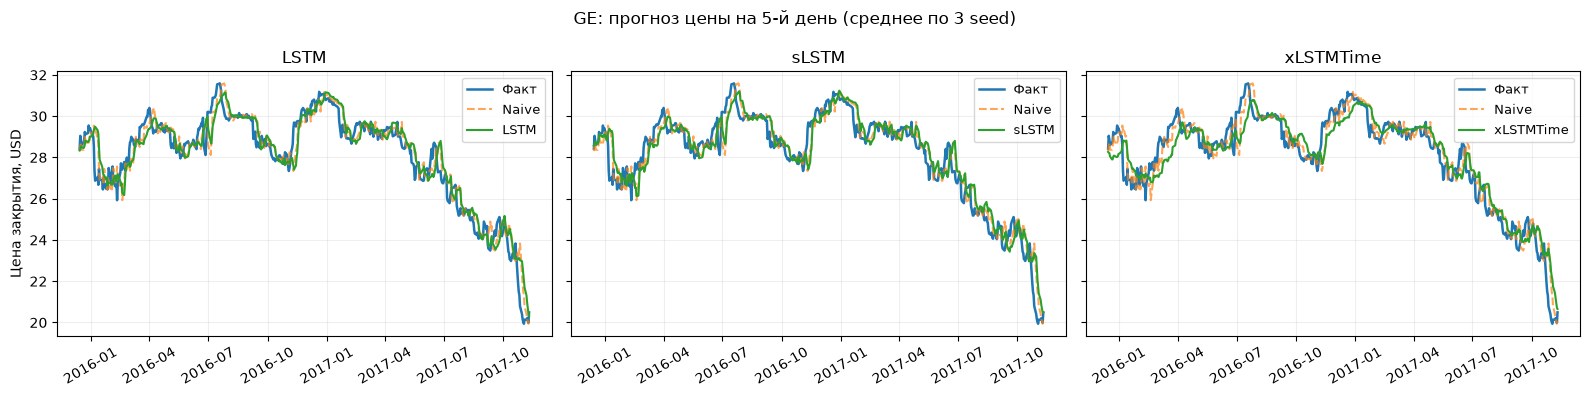

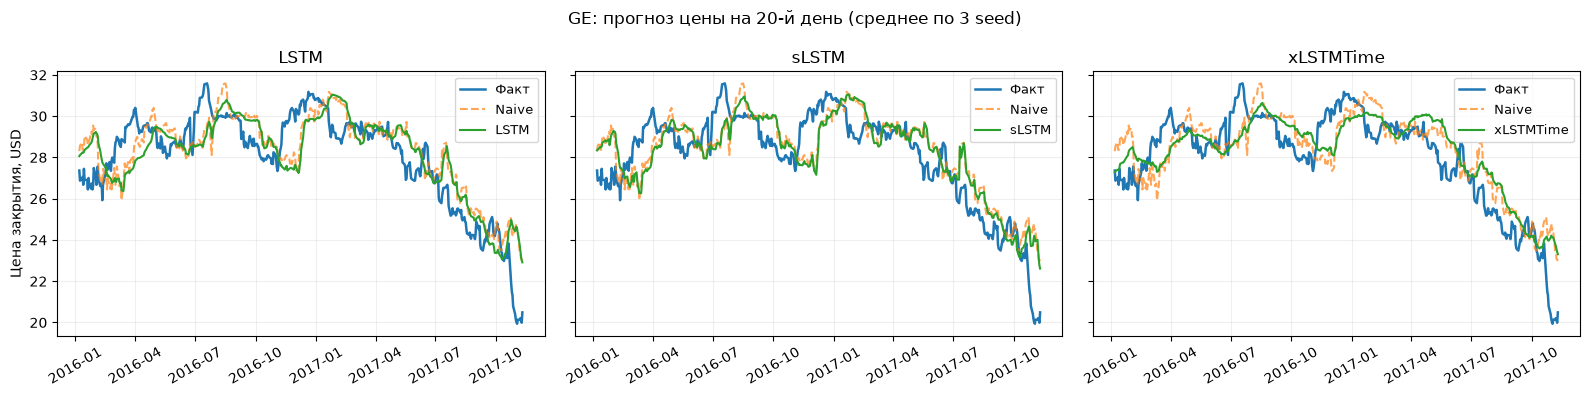

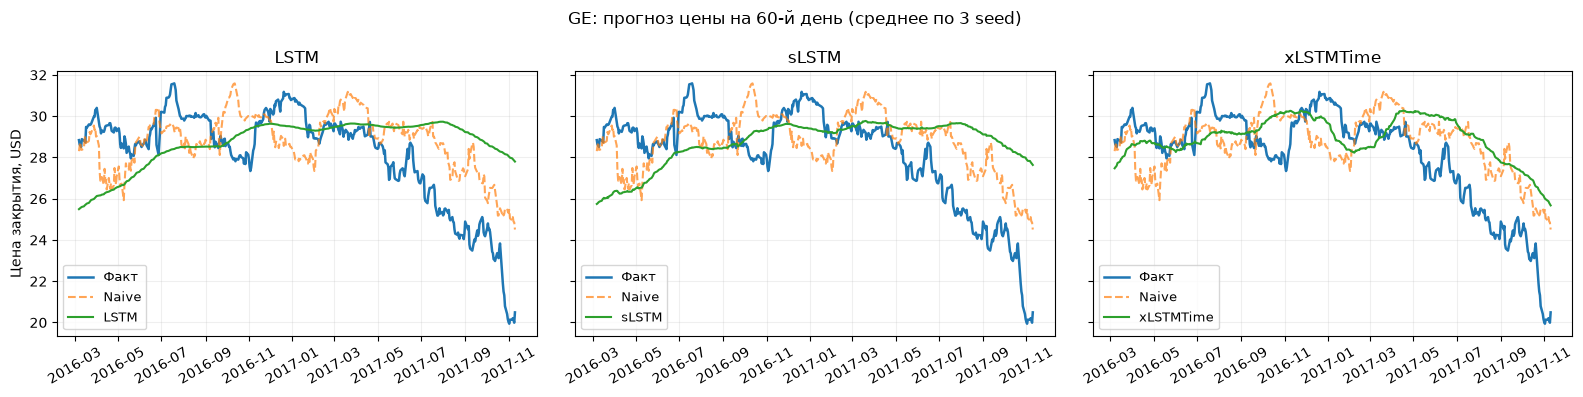

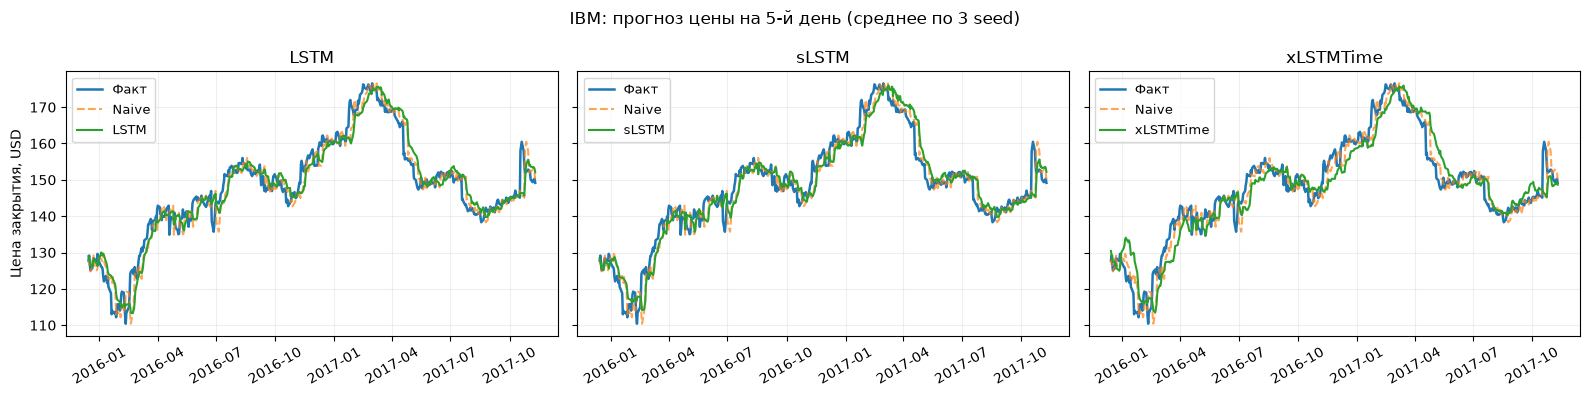

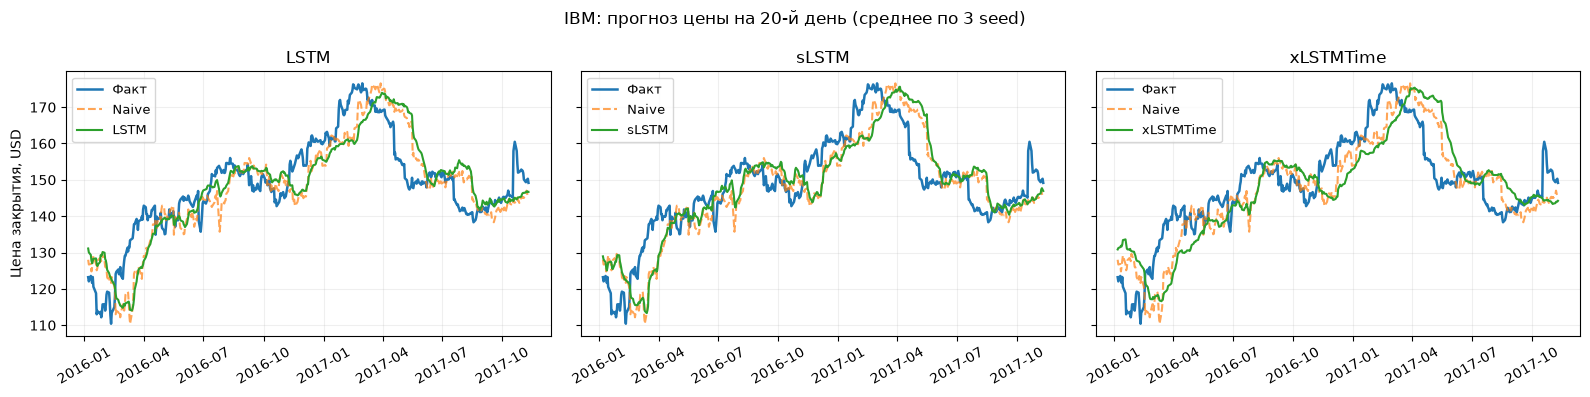

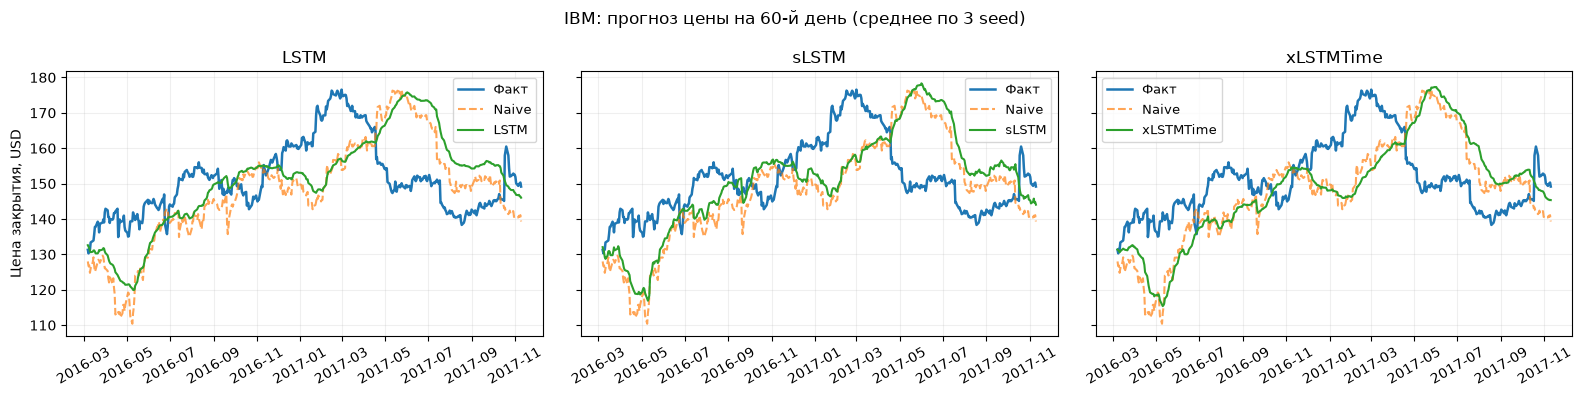

In [20]:
for stock in stocks:
    for horizon in horizons:
        dates = forecast_dates[stock, horizon]
        fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharex=True, sharey=True)

        for ax, name in zip(axes, models):
            predictions = []
            for seed in seeds:
                predictions.append(forecasts[stock, horizon, name, seed])

            mean_prediction = np.mean(predictions, axis=0)
            ax.plot(dates, forecast_truth[stock, horizon], label="Факт", linewidth=1.8)
            ax.plot(dates, forecasts[stock, horizon, "Naive"], "--", alpha=0.7, label="Naive")
            ax.plot(dates, mean_prediction, label=name)
            ax.set_title(name)
            ax.tick_params(axis="x", labelrotation=30)
            ax.grid(alpha=0.2)
            ax.legend(fontsize=9)

        axes[0].set_ylabel("Цена закрытия, USD")
        fig.suptitle(f"{stock}: прогноз цены на {horizon}-й день (среднее по 3 seed)")
        plt.tight_layout()
        plt.show()

## Эксперимент 2

При H=20 сравниваем xLSTMTime без декомпозиции и с окнами 7, 25, 49

In [21]:
ablation_horizon = 20

base = results_runs[(results_runs["model"] == "xLSTMTime") &
                    (results_runs["horizon"] == ablation_horizon)].copy()
base["window"] = "25"
rows = base.to_dict("records")

for stock in stocks:
    print(stock)
    train, val, test, scaler = prepare_data(stock, ablation_horizon)

    for seed in seeds:
        for window in [None, 7, 49]:
            row, model, history = run_model(stock, ablation_horizon, "xLSTMTime",
                                            seed, train, val, test, window=window)

            if window is None:
                row["window"] = "без декомпозиции"
            else:
                row["window"] = str(window)

            rows.append(row)

ablation_runs = pd.DataFrame(rows)
ablation_df = summarize_runs(ablation_runs, ["dataset", "horizon", "model", "window"])

AAPL
SPY
GE
IBM


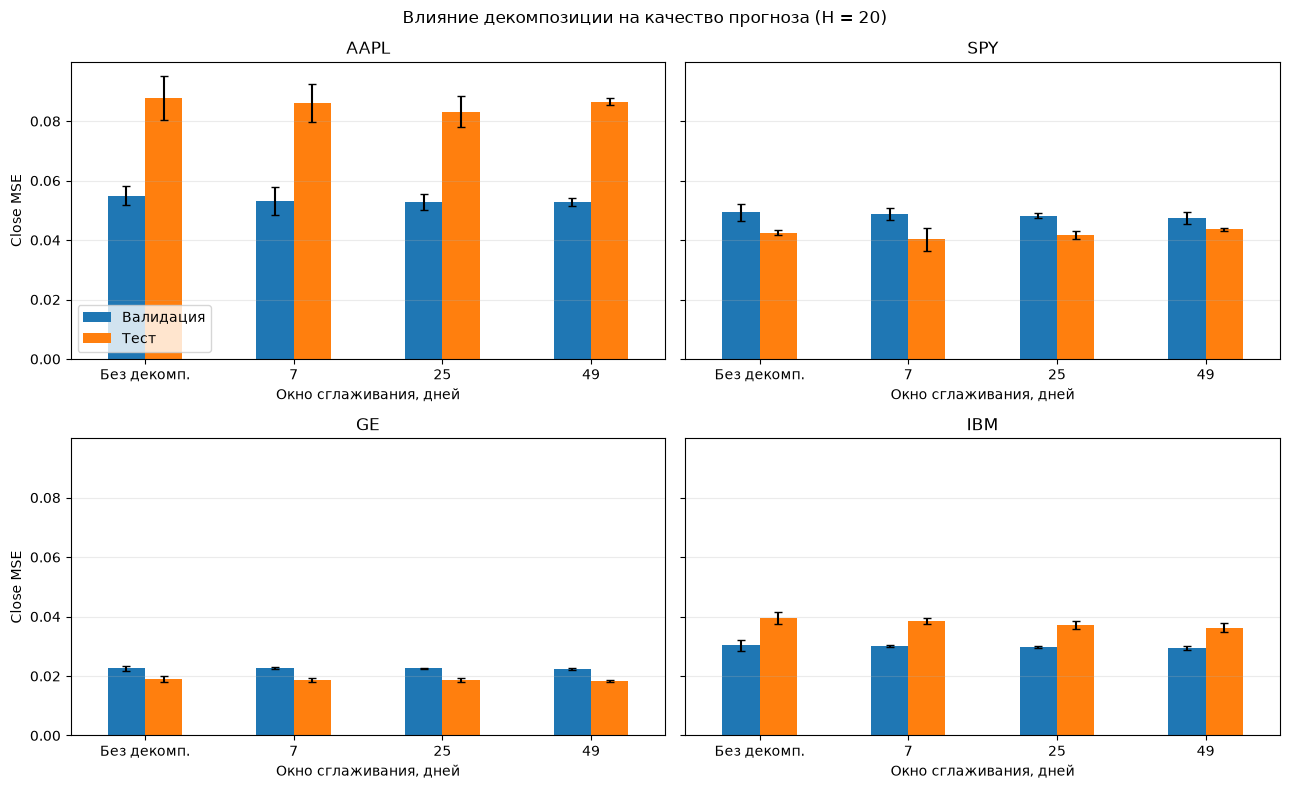

In [36]:
windows = ["без декомпозиции", "7", "25", "49"]

fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharey=True)

for ax, stock in zip(axes.flat, stocks):
    rows = ablation_runs[ablation_runs["dataset"] == stock]

    means = pd.DataFrame(index=windows)
    stds = pd.DataFrame(index=windows)

    for window in windows:
        scores = rows[rows["window"] == window]

        means.loc[window, "Валидация"] = scores["val_Close_MSE"].mean()
        means.loc[window, "Тест"] = scores["Close_MSE"].mean()

        stds.loc[window, "Валидация"] = scores["val_Close_MSE"].std()
        stds.loc[window, "Тест"] = scores["Close_MSE"].std()

    means.plot.bar(yerr=stds, capsize=3, rot=0, ax=ax, legend=False)

    ax.set_title(stock)
    ax.set_ylabel("Close MSE")
    ax.set_xlabel("Окно сглаживания, дней")
    ax.set_xticklabels(["Без декомп.", "7", "25", "49"])
    ax.grid(axis="y", alpha=0.25)

axes[0, 0].legend()
fig.suptitle("Влияние декомпозиции на качество прогноза (H = 20)")
plt.tight_layout()
plt.show()

In [23]:
rows = []
for stock in stocks:
    scores = ablation_df[ablation_df["dataset"] == stock]
    best = scores.sort_values("val_Close_MSE").iloc[0]
    baseline = scores[scores["window"] == "без декомпозиции"].iloc[0]
    rows.append({"dataset": stock, "window": best["window"],
                 "val_Close_MSE": best["val_Close_MSE"], "Close_MSE": best["Close_MSE"],
                 "Close_MSE_std": best["Close_MSE_std"],
                 "Close_MSE без декомпозиции": baseline["Close_MSE"],
                 "выигрыш, %": 100 * (1 - best["Close_MSE"] / baseline["Close_MSE"])})

window_summary = pd.DataFrame(rows).set_index("dataset")
display(window_summary.round(4))

,window,val_Close_MSE,Close_MSE,Close_MSE_std,Close_MSE без декомпозиции,"выигрыш, %"
dataset,,,,,,
AAPL,49,0.0528,0.0865,0.0011,0.0877,1.3122
SPY,49,0.0474,0.0436,0.0004,0.0424,-2.7246
GE,49,0.0223,0.0184,0.0004,0.0190,2.9043
IBM,49,0.0294,0.0362,0.0014,0.0395,8.3210


## Эксперимент 3

При H=20 и окне 25 заменим sLSTM внутри xLSTMTime на обычную LSTM и посмотрим, дает ли сама ячейка sLSTM выигрыш при одинаковой остальной архитектуре

In [24]:
base = results_runs[(results_runs["model"] == "xLSTMTime") &
                    (results_runs["horizon"] == ablation_horizon)].copy()
base["cell"] = "sLSTM"
rows = base.to_dict("records")

for stock in stocks:
    print(stock)
    train, val, test, scaler = prepare_data(stock, ablation_horizon)

    for seed in seeds:
        row, model, history = run_model(stock, ablation_horizon, "xLSTMTime",
                                        seed, train, val, test, cell="lstm")
        row["cell"] = "LSTM"
        rows.append(row)

cell_runs = pd.DataFrame(rows)
cell_runs = cell_runs.drop(columns=["model", "horizon"])
cell_df = summarize_runs(cell_runs, ["dataset", "cell"])

AAPL
SPY
GE
IBM


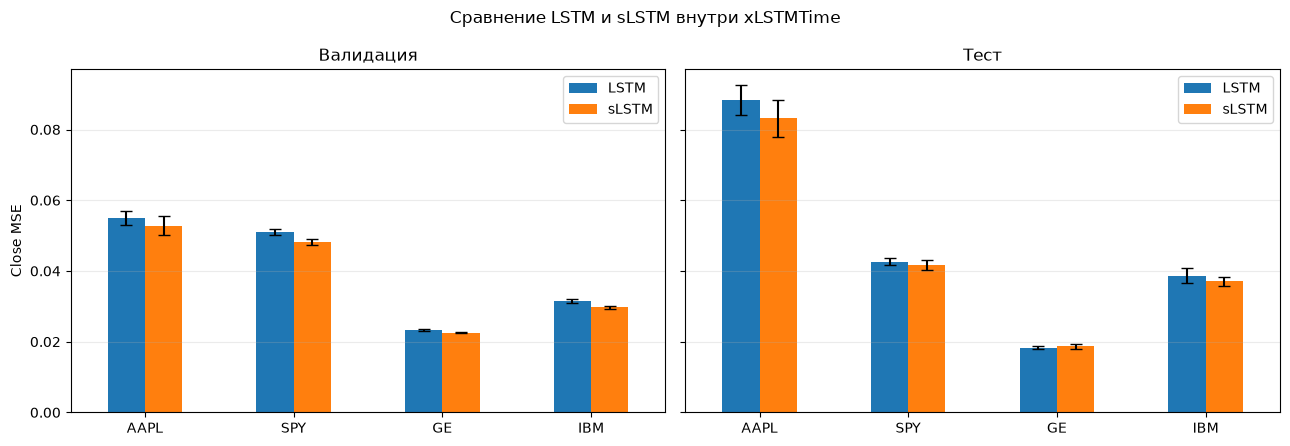

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)

for ax, metric, title in zip(
    axes,
    ["val_Close_MSE", "Close_MSE"],
    ["Валидация", "Тест"]
):
    means = pd.DataFrame(index=stocks)
    stds = pd.DataFrame(index=stocks)

    for cell in ["LSTM", "sLSTM"]:
        scores = cell_runs[cell_runs["cell"] == cell]

        means[cell] = scores.groupby("dataset")[metric].mean()
        stds[cell] = scores.groupby("dataset")[metric].std()

    means.plot.bar(yerr=stds, capsize=4, rot=0, ax=ax)

    ax.set_title(title)
    ax.set_ylabel("Close MSE")
    ax.set_xlabel("")
    ax.grid(axis="y", alpha=0.25)

fig.suptitle("Сравнение LSTM и sLSTM внутри xLSTMTime")
plt.tight_layout()
plt.show()

In [43]:
paired = cell_runs.pivot(index=["dataset", "seed"],
                        columns="cell", values="Close_MSE")

cell_comparison = pd.DataFrame(index=stocks)

for cell in ["LSTM", "sLSTM"]:
    cell_comparison[cell + " mean"] = paired[cell].groupby("dataset").mean()
    cell_comparison[cell + " std"] = paired[cell].groupby("dataset").std()

cell_comparison["Побед sLSTM из 3"] = (
    paired["sLSTM"] < paired["LSTM"]
).groupby("dataset").sum()

display(cell_comparison.round(4))

,LSTM mean,LSTM std,sLSTM mean,sLSTM std,Побед sLSTM из 3
AAPL,0.0883,0.0042,0.0832,0.0052,3
SPY,0.0426,0.0010,0.0417,0.0014,3
GE,0.0183,0.0003,0.0187,0.0008,1
IBM,0.0387,0.0021,0.0371,0.0014,3


## Эксперимент 4

До этого мы минимизировали ошибку по всем признакам, хотя основная цель - прогноз Close. Сравним две функции потерь:
- All: MSE по всем пяти признакам.
- Close: MSE только по цене закрытия.

In [27]:
base = results_runs[results_runs["model"] != "Naive"].copy()
base["loss"] = "All"
rows = base.to_dict("records")

for stock in stocks:
    print(stock)
    for horizon in horizons:
        train, val, test, scaler = prepare_data(stock, horizon)
        for seed in seeds:
            for name in models:
                row, model, history = run_model(stock, horizon, name, seed,
                                                train, val, test, close_only=True)
                row["loss"] = "Close"
                rows.append(row)

loss_runs = pd.DataFrame(rows)
loss_df = summarize_runs(loss_runs, ["dataset", "horizon", "model", "loss"])

AAPL
SPY
GE
IBM


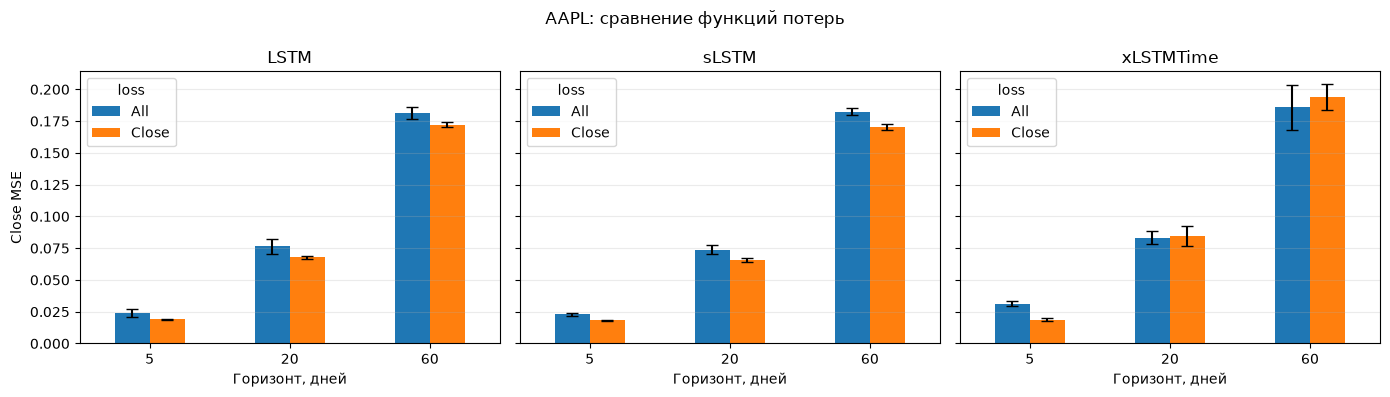

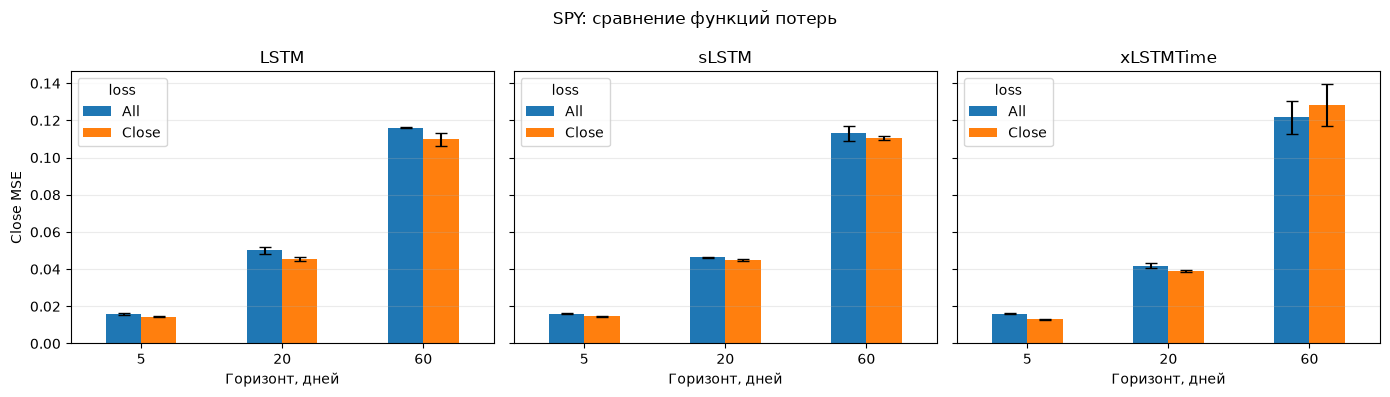

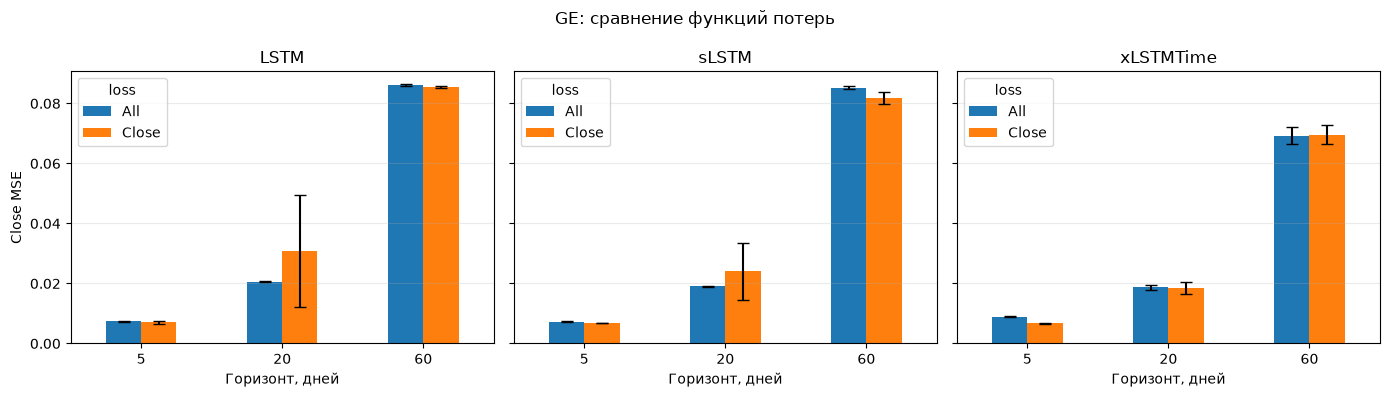

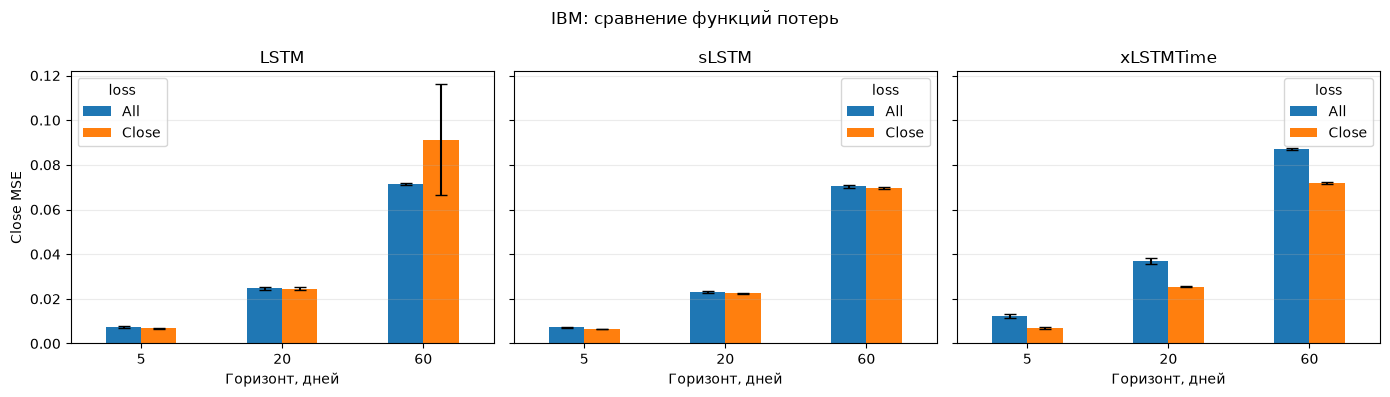

In [39]:
for stock in stocks:
    fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)

    for ax, name in zip(axes, models):
        rows = loss_runs[(loss_runs["dataset"] == stock) &
                         (loss_runs["model"] == name)]

        means = rows.groupby(["horizon", "loss"])["Close_MSE"].mean().unstack()
        stds = rows.groupby(["horizon", "loss"])["Close_MSE"].std().unstack()

        means.plot.bar(yerr=stds, capsize=4, rot=0, ax=ax)

        ax.set_title(name)
        ax.set_xlabel("Горизонт, дней")
        ax.set_ylabel("Close MSE")
        ax.grid(axis="y", alpha=0.25)

    fig.suptitle(stock + ": сравнение функций потерь")
    plt.tight_layout()
    plt.show()

In [40]:
metrics = ["Close_MSE", "MSE", "val_Close_MSE"]

means = loss_runs.groupby(
    ["model", "loss", "dataset", "horizon"]
)[metrics].mean()

loss_summary = means.groupby(["model", "loss"]).median()

display(loss_summary.round(4))

Close_MSE     MSE  val_Close_MSE
model     loss                                   
LSTM      All       0.0374  0.1527         0.0272
          Close     0.0381  0.2451         0.0262
sLSTM     All       0.0348  0.1523         0.0264
          Close     0.0345  0.2372         0.0260
xLSTMTime All       0.0394  0.1503         0.0303
          Close     0.0322  0.1881         0.0277

In [42]:
loss_keys = ["dataset", "horizon", "model"]

test = loss_df.pivot(index=loss_keys, columns="loss", values="Close_MSE")
val = loss_df.pivot(index=loss_keys, columns="loss", values="val_Close_MSE")

print("Всего сравнений:", len(test))
print("Close лучше:", (test["Close"] < test["All"]).sum())
print("All лучше:", (test["All"] < test["Close"]).sum())

correct = 0

for index in test.index:
    loss = val.loc[index].idxmin()

    if test.loc[index, loss] == test.loc[index].min():
        correct += 1

print("Close выбрана по валидации:", (val["Close"] < val["All"]).sum())
print("Правильный выбор по валидации:", correct, "из", len(test))

Всего сравнений: 36
Close лучше: 29
All лучше: 7
Close выбрана по валидации: 31
Правильный выбор по валидации: 32 из 36


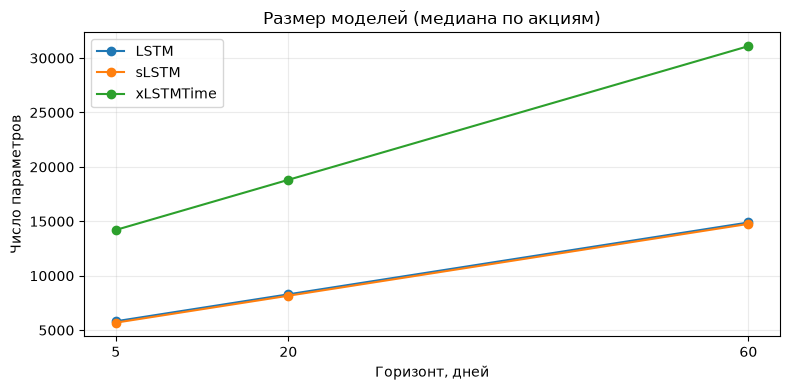

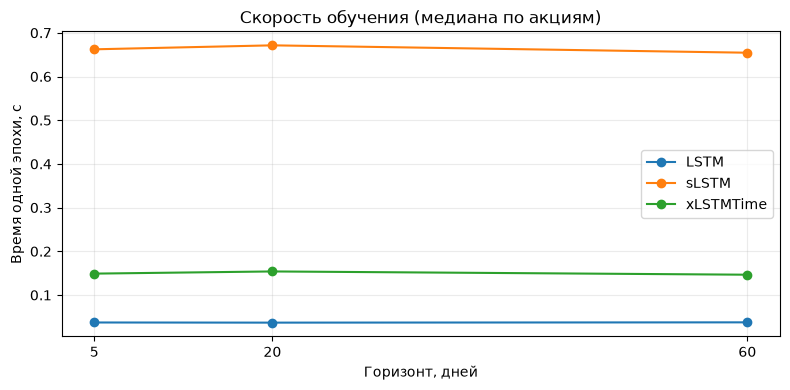

In [31]:
trained = results_df[results_df["model"] != "Naive"]

for metric, title, ylabel in [
    ("parameters", "Размер моделей", "Число параметров"),
    ("seconds_per_epoch", "Скорость обучения", "Время одной эпохи, с")
]:
    plt.figure(figsize=(8, 4))
    for name in models:
        rows = trained[trained["model"] == name]
        values = rows.groupby("horizon")[metric].median()
        plt.plot(values.index, values, marker="o", label=name)

    plt.title(title + " (медиана по акциям)")
    plt.xlabel("Горизонт, дней")
    plt.ylabel(ylabel)
    plt.xticks(horizons)
    plt.grid(alpha=0.25)
    plt.legend()
    plt.tight_layout()
    plt.show()